# 01 — Dataset Feasibility Audit (IEEE-CIS Fraud Detection)

**Project:** Fraud Detection Under Limited Review Capacity: A Temporally Validated Study of Gradient-Boosting Models and Decision Policies
**Programme / module:** MSc Data Science, University of Greenwich — COMP1885 Individual Project
**Notebook status:** pre-protocol-freeze feasibility audit. **No models are trained, no thresholds are tuned, and the proposed final-test period is not analysed.**

### Purpose
To decide, on evidence, whether the labelled IEEE-CIS training data (`train_transaction.csv`, `train_identity.csv`) can support the proposed research design (main RQ, RQ1–RQ3, H1–H3), and which parts of that design have to change before the protocol is frozen.

### How to read the conclusions
Every substantive claim is tagged with where it comes from:

| Tag | Meaning |
|---|---|
| **[D]** | Observed in this dataset by this notebook |
| **[L]** | Published literature or an authoritative methodological source (numbered references in §References) |
| **[G]** | University of Greenwich guidance or policy |
| **[I]** | Inference or recommendation by the author of this audit. It is reasoned but not directly observed or published. |

### Test-set protection protocol used in this notebook
1. **Stage 1 (pre-freeze, full 182 days):** structural inspection only: file integrity, shapes, dtypes, keys, joins, duplicates, high-level missingness, `TransactionDT` range and transaction *volume*. The `isFraud` column is removed from the frame on load (`_sealed_label`), and only its name, dtype and value domain {0, 1} are checked. **No prevalence, fraud count or feature–target relationship is computed on the full data.** Every full-data inspection is logged (§3.6).
2. **Stage 2 (freeze):** a chronological, day-aligned split is chosen **from transaction volume alone** and hashed.
3. **Stage 3 (post-freeze, development data only):** labels are attached **only** to Train / V1 / V2 rows. The label vector for the Test period is then deleted from memory. All target-driven analysis, drift analysis and feasibility estimates use Train / V1 / V2 only. Where a Test-period quantity is needed (e.g. an expected fraud count for a power estimate), it is **projected from V2**, never observed.

> **Reproducibility.** Run from the repository root or from `notebooks/`. Raw files are expected in `data/raw/`. Everything is deterministic (no sampling). Peak memory is roughly 6 GB.

## 1. Setup

In [1]:
import hashlib
import platform
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
TX_PATH = RAW / "train_transaction.csv"
ID_PATH = RAW / "train_identity.csv"
SECONDS_PER_DAY = 86_400
SEED = 20260923  # only used if any sampling is needed; the audit itself is deterministic

# Plot style: one categorical order, recessive axes, no dual axes.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "band": "#f1f0ec"}
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 3.6), "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink"],
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 9.5,
})

# Every inspection of the FULL dataset (all 182 days) before the split freeze is logged here.
FULL_DATA_LOG = []
def log_full(item, uses_label=False, detail=""):
    FULL_DATA_LOG.append({"inspection": item, "uses isFraud values": uses_label, "detail": detail})

print("Python   ", sys.version.split()[0], "|", platform.platform())
import scipy
for m in (pd, np, scipy, matplotlib):
    print(f"{m.__name__:<10} {m.__version__}")
print("Repo root", ROOT)

Python    3.12.3 | Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
pandas     3.0.6
numpy      2.5.3
scipy      1.18.1
matplotlib 3.11.2
Repo root /home/chathuranga/projects/fraud-detection-review-capacity


---
# STAGE 1 — Pre-freeze structural inspection (full dataset, labels sealed)

## 2. (A) Dataset integrity

### 2.1 Files, sizes and checksums
The SHA-256 digests are recorded so that a later dataset manifest can verify that the same raw files were used.

In [2]:
def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

file_rows = []
for p in (TX_PATH, ID_PATH):
    assert p.exists(), f"Missing raw file: {p}"
    file_rows.append({"file": p.name, "exists": p.exists(), "size_MB": round(p.stat().st_size / 1e6, 1),
                      "sha256": sha256(p)})
files_df = pd.DataFrame(file_rows)
log_full("File existence, size, SHA-256", detail="byte-level only")
files_df

,file,exists,size_MB,sha256
0,train_transaction.csv,True,683.4,3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a60c32284ca6283d642
1,train_identity.csv,True,26.5,b63c725d8377be90a995268d97f347c17d456b95db45807adcf9f59cd603c37c


### 2.2 Load, seal the target, and report shapes

In [3]:
tx = pd.read_csv(TX_PATH)
idn = pd.read_csv(ID_PATH)

# Seal the label immediately. Until the split is frozen, only its column name, dtype and
# value domain are checked -- no prevalence, no fraud counts, no feature-target relationships.
assert "isFraud" in tx.columns
_sealed_label = tx.pop("isFraud")
label_domain_ok = bool(_sealed_label.isna().sum() == 0 and set(_sealed_label.unique()) <= {0, 1})
log_full("Target column: name, dtype, domain {0,1}, no missing", uses_label=True,
         detail="domain check only; no counts or rates computed")

shape_df = pd.DataFrame({
    "table": ["train_transaction", "train_identity"],
    "rows": [len(tx), len(idn)],
    "columns (incl. key; transaction incl. sealed isFraud)": [tx.shape[1] + 1, idn.shape[1]],
    "memory_MB": [round(tx.memory_usage(deep=True).sum() / 1e6), round(idn.memory_usage(deep=True).sum() / 1e6)],
})
log_full("Row/column counts, memory")
print("isFraud dtype:", _sealed_label.dtype, "| binary {0,1} with no missing values:", label_domain_ok)
shape_df

isFraud dtype: int64 | binary {0,1} with no missing values: True


,table,rows,columns (incl. key; transaction incl. sealed isFraud),memory_MB
0,train_transaction,590540,394,1874
1,train_identity,144233,41,59


### 2.3 Column types

In [4]:
def dtype_summary(df, name):
    s = df.dtypes.astype(str).value_counts().rename("n_columns").to_frame()
    s.insert(0, "table", name)
    return s

display(pd.concat([dtype_summary(tx, "train_transaction (label sealed)"), dtype_summary(idn, "train_identity")]))
print("String columns, transaction:", [c for c in tx.columns if not pd.api.types.is_numeric_dtype(tx[c])])
print("String columns, identity   :", [c for c in idn.columns if not pd.api.types.is_numeric_dtype(idn[c])])
log_full("Column names and dtypes")

,table,n_columns
float64,train_transaction (label sealed),376
str,train_transaction (label sealed),14
int64,train_transaction (label sealed),3
float64,train_identity,23
str,train_identity,17
int64,train_identity,1


String columns, transaction: ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']
String columns, identity   : ['id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


**Note on dtypes [D].** Several variables that are conceptually *nominal* are stored as numbers (`card1`, `card2`, `card3`, `card5`, `addr1`, `addr2`, and most `id_*` codes). Whether they are treated as numeric or categorical is a modelling decision. That decision interacts directly with the LightGBM-vs-CatBoost comparison (§9), so it must be fixed in the protocol, not left to library defaults.

### 2.4 Keys and join structure

In [5]:
tx_ids, id_ids = tx["TransactionID"], idn["TransactionID"]
matched = id_ids.isin(tx_ids)
join_df = pd.DataFrame({
    "check": [
        "TransactionID unique in transaction table",
        "TransactionID unique in identity table",
        "Identity rows matched to a transaction",
        "Identity rows with no matching transaction (orphans)",
        "Transactions with an identity record",
        "Transactions without an identity record",
    ],
    "value": [
        tx_ids.is_unique, id_ids.is_unique, int(matched.sum()), int((~matched).sum()),
        int(tx_ids.isin(id_ids).sum()), int((~tx_ids.isin(id_ids)).sum()),
    ],
})
join_df["% of relevant table"] = [None, None, 100 * matched.mean(), 100 * (~matched).mean(),
                                 100 * tx_ids.isin(id_ids).mean(), 100 * (~tx_ids.isin(id_ids)).mean()]

# The join must be LEFT (transaction <- identity), one-to-one, row-preserving.
_probe = tx[["TransactionID"]].merge(idn[["TransactionID"]], on="TransactionID", how="left", validate="one_to_one")
assert len(_probe) == len(tx)
print("Left join is one-to-one and preserves", len(_probe), "transaction rows.")
log_full("Key uniqueness and join structure")
join_df.round(2)

Left join is one-to-one and preserves 590540 transaction rows.


,check,value,% of relevant table
0,TransactionID unique in transaction table,True,NaN
1,TransactionID unique in identity table,True,NaN
2,Identity rows matched to a transaction,144233,100.00
3,Identity rows with no matching transaction (orphans),0,0.00
4,Transactions with an identity record,144233,24.42
5,Transactions without an identity record,446307,75.58


**Findings [D].**
- `TransactionID` is unique in both tables. Every identity row matches exactly one transaction (no orphans).
- Only **24.4 %** of transactions have an identity record. The correct join is therefore a **left join from transaction to identity**. It is one-to-one and preserves all 590,540 rows.
- Because identity is absent for about 3 in 4 transactions, "identity present / absent" is a structural property of the data rather than ordinary missingness. It is a natural candidate slice for later false-negative analysis (§13).

### 2.5 Duplicate rows

In [6]:
feat_cols_tx = [c for c in tx.columns if c != "TransactionID"]
feat_cols_id = [c for c in idn.columns if c != "TransactionID"]
dup_tx_full = int(tx.duplicated().sum())
dup_tx_feat = int(tx.duplicated(subset=feat_cols_tx).sum())
dup_tx_feat_nodt = int(tx.duplicated(subset=[c for c in feat_cols_tx if c != "TransactionDT"]).sum())
dup_id_feat = int(idn.duplicated(subset=feat_cols_id).sum())
dups_df = pd.DataFrame({
    "check": ["Exact duplicate transaction rows (incl. TransactionID)",
              "Transaction rows duplicated on all features (excl. TransactionID, label sealed)",
              "... and also ignoring TransactionDT",
              "Identity rows duplicated on all identity features (excl. TransactionID)"],
    "count": [dup_tx_full, dup_tx_feat, dup_tx_feat_nodt, dup_id_feat],
})
log_full("Duplicate-row checks", detail="features only; label sealed")
dups_df

,check,count
0,Exact duplicate transaction rows (incl. TransactionID),0
1,"Transaction rows duplicated on all features (excl. TransactionID, label sealed)",3
2,... and also ignoring TransactionDT,1503
3,Identity rows duplicated on all identity features (excl. TransactionID),3767


**Findings [D].** There are no exact duplicate records. Only 3 transaction rows are identical on every feature including `TransactionDT`. Ignoring the timestamp, 1,503 rows repeat an earlier feature vector, which is plausible for repeated purchases by the same customer. Identity-row duplication (3,767) is expected: the same device and browser configuration recurs. None of this is a data-quality problem in itself. Whether repeated feature vectors carry *conflicting* labels is checked post-freeze on development data only (§15).

### 2.6 High-level missingness by feature group (full data)

In [7]:
def feature_group(col):
    if col in ("TransactionID",): return "Key"
    if col == "TransactionDT": return "Time"
    if col == "TransactionAmt": return "Amount"
    if col == "ProductCD": return "Product"
    if col.startswith("card"): return "Card"
    if col in ("addr1", "addr2"): return "Address"
    if col in ("dist1", "dist2"): return "Distance"
    if col.endswith("emaildomain"): return "Email domain"
    if col[0] == "C" and col[1:].isdigit(): return "C (counts)"
    if col[0] == "D" and col[1:].isdigit(): return "D (timedeltas)"
    if col[0] == "M" and col[1:].isdigit(): return "M (match flags)"
    if col[0] == "V" and col[1:].isdigit(): return "V (engineered)"
    if col in ("DeviceType", "DeviceInfo"): return "Device"
    if col.startswith("id_"): return "Identity id_01-38"
    return "Other"

GROUP_ORDER = ["Time", "Amount", "Product", "Card", "Address", "Distance", "Email domain", "C (counts)",
               "D (timedeltas)", "M (match flags)", "V (engineered)", "Identity id_01-38", "Device"]

def missingness_by_group(df, cols):
    miss = df[cols].isna().mean() * 100
    g = pd.Series({c: feature_group(c) for c in cols})
    out = miss.groupby(g).agg(n_columns="size", mean_missing_pct="mean", min_missing_pct="min", max_missing_pct="max")
    return out.reindex([x for x in GROUP_ORDER if x in out.index]).round(1)

miss_tx_full = missingness_by_group(tx, [c for c in tx.columns if c != "TransactionID"])
miss_id_full = missingness_by_group(idn, [c for c in idn.columns if c != "TransactionID"])
log_full("High-level missingness by feature group")
print("Transaction table, all 182 days (% missing):")
display(miss_tx_full)
print("Identity table, among the 144,233 rows that exist (% missing within identity rows):")
display(miss_id_full)

Transaction table, all 182 days (% missing):


,n_columns,mean_missing_pct,min_missing_pct,max_missing_pct
Time,1,0.0,0.0,0.0
Amount,1,0.0,0.0,0.0
Product,1,0.0,0.0,0.0
Card,6,0.5,0.0,1.5
Address,2,11.1,11.1,11.1
Distance,2,76.6,59.7,93.6
Email domain,2,46.4,16.0,76.8
C (counts),14,0.0,0.0,0.0
D (timedeltas),15,58.2,0.2,93.4
M (match flags),9,49.9,28.7,59.3


Identity table, among the 144,233 rows that exist (% missing within identity rows):


,n_columns,mean_missing_pct,min_missing_pct,max_missing_pct
Identity id_01-38,38,37.9,0.0,96.7
Device,2,10.0,2.4,17.7


### 2.7 Obvious data-quality checks

In [8]:
num_cols = [c for c in tx.columns if pd.api.types.is_numeric_dtype(tx[c]) and c not in ("TransactionID", "TransactionDT")]
neg = (tx[num_cols] < 0).sum()
neg = neg[neg > 0].sort_values(ascending=False)
nunique = tx.nunique(dropna=True)
amt = tx["TransactionAmt"]
cents = (amt * 100).round(6)
quality = pd.DataFrame({"check": [
    "Columns with >90% missing (transaction table)",
    "Columns with a single observed value (transaction table)",
    "Numeric columns containing negative values",
    "TransactionAmt min / max",
    "TransactionAmt <= 0",
    "TransactionAmt with more than 2 decimal places (share)",
], "value": [
    int((tx.isna().mean() > 0.9).sum()),
    list(nunique[nunique <= 1].index),
    f"{len(neg)} columns: " + ", ".join(f"{c} ({n})" for c, n in neg.head(12).items()) + (" ..." if len(neg) > 12 else ""),
    f"{amt.min():.3f} / {amt.max():,.2f}",
    int((amt <= 0).sum()),
    f"{100 * (cents != cents.round(0)).mean():.1f}%",
]})
log_full("Obvious data-quality checks", detail="value ranges, constant columns, negatives; no label")
quality

,check,value
0,Columns with >90% missing (transaction table),2
1,Columns with a single observed value (transaction table),[]
2,Numeric columns containing negative values,"6 columns: D4 (15), D15 (15), D11 (7), D6 (3), D14 (3), D12 (2)"
3,TransactionAmt min / max,"0.251 / 31,937.39"
4,TransactionAmt <= 0,0
5,TransactionAmt with more than 2 decimal places (share),10.5%


**Findings [D].**
- Missingness is heavy and **structured**. D, V, M, distance and email-domain groups are 43–77 % missing on average, and 2 columns are more than 90 % missing. No column is constant.
- A handful of negative values occur in six D columns (≤ 15 rows each). D columns are described by the organiser as time deltas, so these are probably artefacts. They are too few to matter and will not be corrected.
- `TransactionAmt` is strictly positive (0.251 – 31,937.39). **10.5 %** of amounts have more than two decimal places. **[I]** This is consistent with currency conversion. The organiser describes the field as the payment amount in USD [L38], but whether each transaction's original currency and conversion are recoverable is not documented.

## 3. (C) Temporal structure — structural part (volume only)

In [9]:
dt = tx["TransactionDT"]
tx["day"] = (dt // SECONDS_PER_DAY).astype(int)          # relative day index; NOT a calendar date
tx["hour_of_rel_day"] = ((dt % SECONDS_PER_DAY) // 3600).astype(int)
daily_n = tx.groupby("day").size()

time_df = pd.DataFrame({"quantity": [
    "TransactionDT min (s)", "TransactionDT max (s)", "Span (days)", "Relative-day index range",
    "Distinct relative days present", "Rows sorted by TransactionDT", "TransactionID increases with TransactionDT",
    "Transactions sharing an identical TransactionDT with another row",
    "Mean / median transactions per relative day", "Min / max transactions per relative day",
    "Coefficient of variation of daily volume",
    "Lag-1 / lag-7 autocorrelation of daily volume",
], "value": [
    f"{dt.min():,}", f"{dt.max():,}", f"{(dt.max() - dt.min()) / SECONDS_PER_DAY:.2f}",
    f"{tx['day'].min()} - {tx['day'].max()}", tx["day"].nunique(),
    bool(dt.is_monotonic_increasing), bool(tx["TransactionID"].is_monotonic_increasing and dt.is_monotonic_increasing),
    int(dt.duplicated(keep=False).sum()),
    f"{daily_n.mean():,.0f} / {daily_n.median():,.0f}", f"{daily_n.min():,} / {daily_n.max():,}",
    f"{daily_n.std() / daily_n.mean():.3f}",
    f"{daily_n.autocorr(1):.2f} / {daily_n.autocorr(7):.2f}",
]})
log_full("TransactionDT range, ordering, daily and hourly volume", detail="counts only; no label")
time_df

,quantity,value
0,TransactionDT min (s),"86,400"
1,TransactionDT max (s),"15,811,131"
2,Span (days),182.00
3,Relative-day index range,1 - 182
4,Distinct relative days present,182
5,Rows sorted by TransactionDT,True
6,TransactionID increases with TransactionDT,True
7,Transactions sharing an identical TransactionDT with another row,33932
8,Mean / median transactions per relative day,"3,245 / 3,050"
9,Min / max transactions per relative day,"2,048 / 6,852"


**Findings [D].**
- `TransactionDT` runs from 86,400 s to 15,811,131 s, which is **182.0 days**. With `day = TransactionDT // 86,400` this gives relative days **1–182**, and all 182 are present.
- Rows are **already sorted by `TransactionDT`**, and `TransactionID` is monotone in time. **`TransactionID` is therefore a disguised timestamp and must not be used as a feature** (§16).
- `TransactionDT` is an offset from an **undisclosed** reference time [L38]. No calendar dates, weekdays or holidays can be claimed. "Day" throughout this project means *relative day*.

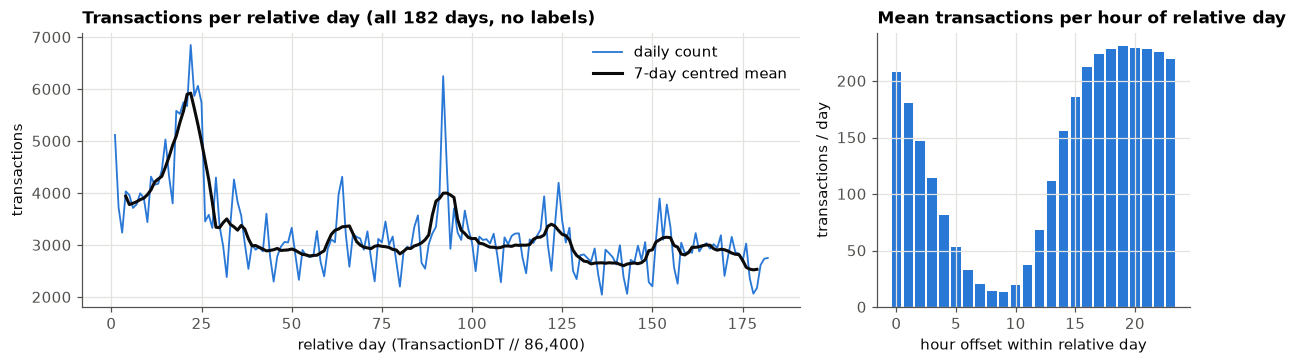

(0, 28]       4524.0
(28, 56]      3064.0
(56, 84]      3039.0
(84, 112]     3285.0
(112, 140]    2946.0
(140, 168]    2887.0
(168, 196]    2692.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2.3, 1]})
ax = axes[0]
ax.plot(daily_n.index, daily_n.values, color=C["blue"], lw=1.2, label="daily count")
ax.plot(daily_n.index, daily_n.rolling(7, center=True).mean(), color=C["ink"], lw=2, label="7-day centred mean")
ax.set_title("Transactions per relative day (all 182 days, no labels)")
ax.set_xlabel("relative day (TransactionDT // 86,400)"); ax.set_ylabel("transactions")
ax.legend(loc="upper right")
ax = axes[1]
hourly = tx.groupby("hour_of_rel_day").size() / tx["day"].nunique()
ax.bar(hourly.index, hourly.values, color=C["blue"], width=0.8)
ax.set_title("Mean transactions per hour of relative day")
ax.set_xlabel("hour offset within relative day"); ax.set_ylabel("transactions / day")
plt.tight_layout(); plt.show()

# Coarse volume comparison in 4-week blocks (structural only)
blocks = pd.cut(daily_n.index, bins=range(0, 183 + 28, 28), right=True)
print(daily_n.groupby(blocks, observed=True).mean().round(0).rename("mean daily volume per 28-day block").to_string())

**Findings [D].**
- Volume is **not stationary**. Days 1–28 average about 4,500 transactions/day, with a spike near days 18–25 (peak 6,852). Later 4-week blocks average about 2,700–3,300/day, with a slow decline towards the end. The coefficient of variation of daily volume is 0.26.
- Lag-1 autocorrelation of daily volume is 0.75, but lag-7 is only 0.50. Short-run persistence is stronger than any weekly cycle. **[I]** Because the weekly pattern is weak, using whole weeks as partition lengths is a tidy convention rather than a strict requirement.
- There is a strong **within-day cycle**: a trough about 8–9 hours after each relative-day boundary. The relative-day boundary therefore falls during *active* hours. **[I]** This matters only for the *daily* top-K policy (R3). It changes which transactions compete for the same day's budget but does not bias any comparison between models. A sensitivity check with a trough-aligned "operational day" is optional.
- **Implication for RQ2 [I].** Daily volume varies by about ±25 % around its mean even without fraud-related drift. A validation-selected *rate* threshold (R2) will therefore produce daily review counts that deviate from a fixed daily budget **even if the score distribution does not drift at all**. RQ2 must separate these two sources of workload error (§6).

### 3.6 Log of full-dataset inspections performed before the split freeze
This table is the audit trail required by the test-protection protocol. **Only row 2 touched the label, and only to confirm that the column exists, is binary and is complete.**

In [ ]:
pre_freeze_log = pd.DataFrame(FULL_DATA_LOG)
pre_freeze_log.index = range(1, len(pre_freeze_log) + 1)
pre_freeze_log

,inspection,uses isFraud values,detail
1,"File existence, size, SHA-256",False,byte-level only
2,"Target column: name, dtype, domain {0,1}, no missing",True,domain check only; no counts or rates computed
3,"Row/column counts, memory",False,
4,Column names and dtypes,False,
5,Key uniqueness and join structure,False,
6,Duplicate-row checks,False,features only; label sealed
7,High-level missingness by feature group,False,
8,Obvious data-quality checks,False,"value ranges, constant columns, negatives; no label"
9,"TransactionDT range, ordering, daily and hourly volume",False,counts only; no label


---
# STAGE 2 — Candidate research split (frozen before any target analysis)

## 4. (D) Choosing a chronological, day-aligned split

### 4.1 Design criteria (decided before looking at any labels)
1. **Chronological and day-aligned.** No transaction of a relative day is split across partitions. Random splits are excluded because fraud labels are propagated across linked transactions [L38], and because temporal evaluation is standard for fraud systems facing concept drift [L5, L6, L8, L25].
2. **Test period long enough for (a) a stable estimate of Recall@capacity and (b) daily-level workload analysis.** At least 4 weeks gives at least 28 daily workload observations.
3. **V2 the same length as Test.** Thresholds and budgets are selected on a window of the same duration as the one they are applied to. This makes "workload transfer" (RQ2) a like-for-like comparison.
4. **V1 long enough for early stopping and hyper-parameter selection** (about 2,500+ frauds expected at the observed ~3.5 % base rate [L38]), but kept short to leave as much Train as possible.
5. **Train as large as possible**, and it must include the early high-volume period, so the model sees the full range of volumes.
6. **Whole weeks** (tidiness, §3).

### 4.2 Candidates (computed from daily volume only)

In [12]:
def describe_split(name, parts):
    rows = []
    for part, (a, b) in parts.items():
        n = int(daily_n.loc[a:b].sum())
        rows.append({"candidate": name, "partition": part, "days": f"{a}-{b}", "n_days": b - a + 1,
                     "rows": n, "% rows": round(100 * n / len(tx), 1), "mean rows/day": round(n / (b - a + 1))})
    return rows

CANDIDATES = {
    "A (recommended)": {"Train": (1, 105), "V1": (106, 126), "V2": (127, 154), "Test": (155, 182)},
    "B (7-day gap)":   {"Train": (1, 98), "V1": (99, 119), "V2": (120, 147), "Gap": (148, 154), "Test": (155, 182)},
    "C (35-day test)": {"Train": (1, 91), "V1": (92, 119), "V2": (120, 147), "Test": (148, 182)},
}
cand_df = pd.DataFrame([r for k, v in CANDIDATES.items() for r in describe_split(k, v)])
cand_df

,candidate,partition,days,n_days,rows,% rows,mean rows/day
0,A (recommended),Train,1-105,105,368632,62.4,3511
1,A (recommended),V1,106-126,21,65544,11.1,3121
2,A (recommended),V2,127-154,28,77822,13.2,2779
3,A (recommended),Test,155-182,28,78542,13.3,2805
4,B (7-day gap),Train,1-98,98,347363,58.8,3545
5,B (7-day gap),V1,99-119,21,63238,10.7,3011
6,B (7-day gap),V2,120-147,28,79954,13.5,2856
7,B (7-day gap),Gap,148-154,7,21443,3.6,3063
8,B (7-day gap),Test,155-182,28,78542,13.3,2805
9,C (35-day test),Train,1-91,91,319934,54.2,3516


**Assessment [I].**

| Candidate | Strength | Weakness |
|---|---|---|
| **A** Train 1–105 / V1 106–126 / V2 127–154 / Test 155–182 | Largest Train (62 %). V2 and Test both 28 days with near-identical volume (2,779 vs 2,805 rows/day). Test is the last 4 weeks. | No explicit gap (discussed below). |
| **B** as A with 7-day gap before Test | Simulates a 1-week label/deployment latency before Test. | Loses 21,443 rows (3.6 %). The gap length is arbitrary because the dataset contains no chargeback report dates. It adds nothing for a model that is *not* refit (see below). |
| **C** 35-day Test | ~27 % more Test rows, so about 11 % smaller detectable effects. | Train shrinks to 54 %. V1 grows beyond what early stopping needs. |

**Is a temporal gap justified?** The only fitted object that sees data adjacent to Test is the set of V2-selected thresholds/calibrator. Under the proposed protocol, **the models are trained on days 1–105 and are not refit**. Model training data therefore already ends **49 days** before the first Test day. A gap would protect against *label latency*: in deployment, the labels of the most recent transactions are not yet known [L6, L8]. **However, this dataset contains no label-report dates, so any gap length would be arbitrary.** Recommendation: **no gap in the primary design.** Add a cheap **sensitivity analysis** in which label-dependent policy choices (R1, R4 calibration) use only V2 days 127–147, a 7-day "latency" gap. This costs no Test access. If the protocol is later changed to refit on Train+V1+V2, a gap becomes necessary.

**Why V1 and V2 must be separate.** Scores on V1 are *selected-on* data: early stopping and hyper-parameter choice optimise V1 performance. Thresholds or calibrators fitted to those scores inherit that optimism. V2 provides genuinely out-of-sample scores for threshold selection and calibration [L28, L29]. V2 is also chronologically closer to Test, which matters because prevalence and composition drift (§14).

**Is one final holdout sufficient?** For RQ1 (a ranking comparison) a single 4-week holdout with about 2,700 frauds is adequate but not generous (§7). **For RQ2 it is weak.** One holdout gives exactly **one** threshold-transfer event (V2 → Test). Daily variation inside Test gives 28 observations of workload error, but they all come from a single calibration origin.

**Would rolling-origin validation add value?** Yes, specifically for RQ2 [L26, L27; L8 recommends "prequential" validation for fraud]. A small, **exploratory**, development-only rolling-origin study would show whether threshold transfer failure is systematic or origin-specific. It could use, for example, 3 origins with 28-day "V2 → next 28 days" transfers, run inside days 1–154 and on one model configuration only. It should not replace the single confirmatory Test evaluation.

### 4.3 Freeze candidate A

In [13]:
SPLIT = CANDIDATES["A (recommended)"]          # <-- frozen for the remainder of this notebook
PART_ORDER = ["Train", "V1", "V2", "Test"]

def assign_partition(day):
    for part, (a, b) in SPLIT.items():
        if a <= day <= b:
            return part
    raise ValueError(day)

part_of_day = {d: assign_partition(d) for d in range(1, 183)}
tx["partition"] = tx["day"].map(part_of_day)

# Integrity assertions: exhaustive, mutually exclusive, contiguous, chronologically ordered.
assert tx["partition"].notna().all()
bounds = tx.groupby("partition")["TransactionDT"].agg(["min", "max"]).loc[PART_ORDER]
assert all(bounds["max"].iloc[i] < bounds["min"].iloc[i + 1] for i in range(3))

def id_hash(ids):
    return hashlib.sha256(np.sort(ids.to_numpy()).astype("int64").tobytes()).hexdigest()[:16]

split_manifest = pd.DataFrame([{
    "partition": p, "relative days": f"{SPLIT[p][0]}-{SPLIT[p][1]}", "n_days": SPLIT[p][1] - SPLIT[p][0] + 1,
    "rows": int((tx["partition"] == p).sum()), "% rows": round(100 * (tx["partition"] == p).mean(), 1),
    "TransactionDT min": int(bounds.loc[p, "min"]), "TransactionDT max": int(bounds.loc[p, "max"]),
    "sha256(TransactionIDs)[:16]": id_hash(tx.loc[tx["partition"] == p, "TransactionID"]),
} for p in PART_ORDER])
split_manifest

,partition,relative days,n_days,rows,% rows,TransactionDT min,TransactionDT max,sha256(TransactionIDs)[:16]
0,Train,1-105,105,368632,62.4,86400,9158384,f3c088aa2f952738
1,V1,106-126,21,65544,11.1,9158441,10972793,cb1325d41dae02a3
2,V2,127-154,28,77822,13.2,10972801,13391998,54edb97bc6b82d4b
3,Test,155-182,28,78542,13.3,13392056,15811131,9f266b2bdf2da9f1


**Frozen split (for this audit; to be copied into `docs/protocol.md` at protocol freeze).** Partitions are exhaustive, mutually exclusive, contiguous and strictly ordered in `TransactionDT` (asserted). The SHA-256 prefix of each partition's sorted `TransactionID`s lets any later pipeline prove it reproduced the same split.

### 4.4 Seal the Test period
From this cell on, the label vector exists **only** for Train / V1 / V2 rows. The full frame and the sealed label are deleted.

In [14]:
# Seal the Test partition. Labels are attached ONLY to development rows (Train, V1, V2).
dev_mask = tx["partition"] != "Test"
TEST_ROWS = int((~dev_mask).sum())
TEST_DAYS = SPLIT["Test"][1] - SPLIT["Test"][0] + 1
TEST_DAILY_N = daily_n.loc[SPLIT["Test"][0]:SPLIT["Test"][1]]   # structural volume only (already seen pre-freeze)

dev = tx.loc[dev_mask].copy()
dev["isFraud"] = _sealed_label.loc[dev.index].astype(int)
del _sealed_label                                             # test labels are no longer held in memory
tx = None                                                      # full frame discarded; only `dev` is used below

dev = dev.merge(idn, on="TransactionID", how="left", validate="one_to_one", indicator="_id")
dev["has_identity"] = dev.pop("_id").eq("both")
assert len(dev) == dev_mask.sum() and set(dev["partition"]) == {"Train", "V1", "V2"}
print(f"Development rows: {len(dev):,} | Test rows sealed: {TEST_ROWS:,} over {TEST_DAYS} days (labels not loaded)")

Development rows: 511,998 | Test rows sealed: 78,542 over 28 days (labels not loaded)


---
# STAGE 3 — Development-data audit (Train, V1, V2 only)

## 5. (B) Target structure

In [15]:
def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

rows = []
for part in ["Train", "V1", "V2", "Dev (all)"]:
    s = dev if part == "Dev (all)" else dev[dev["partition"] == part]
    n, k = len(s), int(s["isFraud"].sum())
    lo, hi = wilson(k, n)
    rows.append({"partition": part, "rows": n, "fraud": k, "legitimate": n - k,
                 "prevalence %": 100 * k / n, "95% Wilson CI %": f"{100*lo:.2f} - {100*hi:.2f}",
                 "imbalance ratio (legit:fraud)": f"{(n - k) / k:.1f} : 1"})
rows.append({"partition": "Test (sealed)", "rows": TEST_ROWS, "fraud": "not computed", "legitimate": "not computed",
             "prevalence %": np.nan, "95% Wilson CI %": "sealed", "imbalance ratio (legit:fraud)": "sealed"})
target_df = pd.DataFrame(rows)
PI = {r["partition"]: r["prevalence %"] / 100 for r in rows if isinstance(r["fraud"], int)}
target_df.round(3)

,partition,rows,fraud,legitimate,prevalence %,95% Wilson CI %,imbalance ratio (legit:fraud)
0,Train,368632,12484,356148,3.387,3.33 - 3.45,28.5 : 1
1,V1,65544,2768,62776,4.223,4.07 - 4.38,22.7 : 1
2,V2,77822,2637,75185,3.389,3.26 - 3.52,28.5 : 1
3,Dev (all),511998,17889,494109,3.494,3.44 - 3.54,27.6 : 1
4,Test (sealed),78542,not computed,not computed,NaN,sealed,sealed


**Findings [D].**
- The target is `isFraud` (binary, complete). Development prevalence is **3.49 %** (17,889 frauds out of 511,998), an imbalance ratio of about **28 : 1**. Train and V2 are both 3.39 %. **V1 is higher at 4.22 %.**
- Test prevalence is **not computed**. The organiser-published full-data figure (about 3.5 % [L38]) is public knowledge, but recomputing it here would reveal the Test rate by subtraction.

**What to call this imbalance [L].** No universal cut-off exists, but the literature is consistent on the order of magnitude:
- Leevy et al. [L2] define *high-class imbalance* as a majority-to-minority ratio between **100 : 1 and 10,000 : 1**. They add that domain experts may call lower ratios "high" when the minority class is hard to model.
- He & Garcia [L1] use "imbalanced" for any unequal class distribution. They illustrate the hard real-world cases with ratios of the order of 100 : 1 to 10,000 : 1.
- Fernández et al. [L4] and Krawczyk [L3] stress that difficulty depends on the imbalance ratio *combined with* class overlap, small disjuncts and dataset shift, not on the ratio alone.
- For contrast, the widely used European card dataset studied by Dal Pozzolo et al. has 0.172 % fraud (~580 : 1), which the fraud literature routinely calls *highly* imbalanced [L5, L6].

**Recommended wording [I].** At about 28 : 1 (3.5 % prevalence) this dataset is **"imbalanced" / "low-prevalence" (moderately imbalanced)**. It is **not** "severely" or "highly" imbalanced by the thresholds above. The phrase *"severe class imbalance"* should be removed from the project documentation. The research difficulty is better described as low prevalence **plus** temporal drift **plus** a review budget smaller than the fraud volume (§6).

### 5.1 Prevalence over time (development days only)

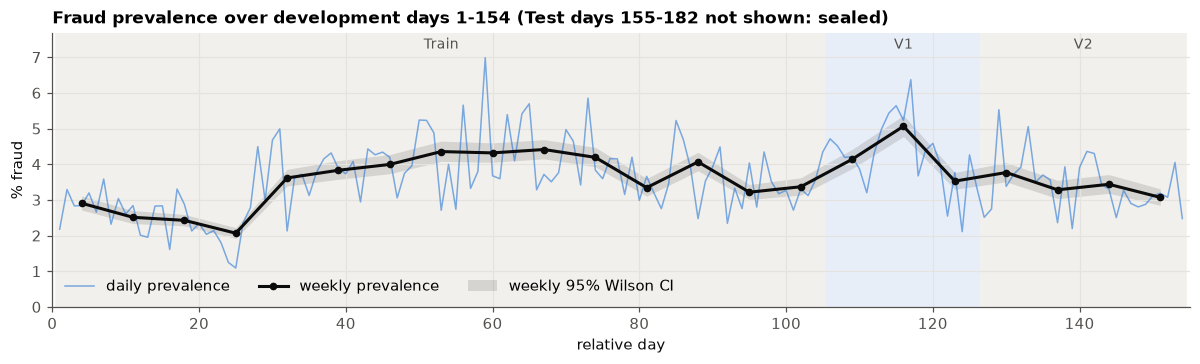

Partition prevalence: chi2=118.5, dof=2, p=1.8e-26, Cramer's V=0.0152
Weekly prevalence range 2.07% - 5.07%; Spearman trend over weeks rho=0.19 (p=0.38)
Daily prevalence: mean 3.62%, SD 1.02 pp, min 1.10%, max 6.99%
Log-odds shift in base rate, V1 -> V2: -0.229; Train -> V2: +0.001


In [16]:
daily_dev = dev.groupby("day").agg(n=("isFraud", "size"), fraud=("isFraud", "sum"))
daily_dev["prev"] = daily_dev["fraud"] / daily_dev["n"]
weekly = dev.assign(week=(dev["day"] - 1) // 7 + 1).groupby("week").agg(
    n=("isFraud", "size"), fraud=("isFraud", "sum"), first_day=("day", "min"))
weekly["prev"] = weekly["fraud"] / weekly["n"]
ci = np.array([wilson(k, n) for k, n in zip(weekly["fraud"], weekly["n"])])

fig, ax = plt.subplots(figsize=(11, 3.4))
for part, (a, b) in SPLIT.items():
    if part != "Test":
        ax.axvspan(a - 0.5, b + 0.5, color=C["band"] if part != "V1" else "#e8eef8", zorder=0)
        ax.text((a + b) / 2, 7.25, part, ha="center", color=C["ink2"], fontsize=9)
ax.plot(daily_dev.index, 100 * daily_dev["prev"], color=C["blue"], lw=1, alpha=0.6, label="daily prevalence")
ax.plot(weekly["first_day"] + 3, 100 * weekly["prev"], color=C["ink"], marker="o", ms=4, lw=2, label="weekly prevalence")
ax.fill_between(weekly["first_day"] + 3, 100 * ci[:, 0], 100 * ci[:, 1], color=C["ink"], alpha=0.12, lw=0,
                label="weekly 95% Wilson CI")
ax.set_xlim(0, 155); ax.set_ylim(0, 7.7)
ax.set_title("Fraud prevalence over development days 1-154 (Test days 155-182 not shown: sealed)")
ax.set_xlabel("relative day"); ax.set_ylabel("% fraud"); ax.legend(loc="lower left", ncol=3)
plt.tight_layout(); plt.show()

# Heterogeneity of prevalence across partitions and weeks (large n: report effect sizes, not only p-values)
ct = pd.crosstab(dev["partition"], dev["isFraud"]).loc[["Train", "V1", "V2"]]
chi2, pval, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
rho, rho_p = stats.spearmanr(weekly.index, weekly["prev"])
logit = lambda p: np.log(p / (1 - p))
print(f"Partition prevalence: chi2={chi2:.1f}, dof={dof}, p={pval:.2g}, Cramer's V={cramers_v:.4f}")
print(f"Weekly prevalence range {100*weekly['prev'].min():.2f}% - {100*weekly['prev'].max():.2f}%; "
      f"Spearman trend over weeks rho={rho:.2f} (p={rho_p:.2g})")
print(f"Daily prevalence: mean {100*daily_dev['prev'].mean():.2f}%, SD {100*daily_dev['prev'].std():.2f} pp, "
      f"min {100*daily_dev['prev'].min():.2f}%, max {100*daily_dev['prev'].max():.2f}%")
print(f"Log-odds shift in base rate, V1 -> V2: {logit(PI['V2']) - logit(PI['V1']):+.3f}; Train -> V2: {logit(PI['V2']) - logit(PI['Train']):+.3f}")

**Findings [D].**
- Weekly prevalence ranges from about **2.1 % to 5.1 %** with **no monotone trend** (Spearman ρ = 0.19, p = 0.38). Daily prevalence ranges from about 1.1 % to 7.0 % (SD ≈ 1.0 pp).
- Prevalence was **lowest (≈ 2–2.5 %) during the early high-volume period** (days 1–28) and rose to ≈ 3.5–4.5 % afterwards. **[I]** Extra volume in that period did not bring proportionally more fraud. Train therefore mixes two regimes, which is one more reason to calibrate on recent data.
- The Train/V1/V2 difference is highly "significant" (χ², p ≈ 10⁻²⁶) but **tiny as an effect size** (Cramér's V = 0.015). With half a million rows, p-values are uninformative here. The practically relevant quantity is the **log-odds shift of −0.23 between V1 and V2**. A calibrator fitted on V1 would *over*-predict risk on V2-like data by roughly that amount on the logit scale. This is a concrete reason to calibrate on V2, not V1 (§12).
- **[I]** The fraud rate is episodic rather than trending. A single Test period may therefore land on an unusually high- or low-fraud window. This is another argument for reporting uncertainty and for the rolling-origin supplement.

## 6. (E) Review-capacity feasibility

Capacity scenarios are **simulated research scenarios, not real institutional capacities**. Following the protocol, a scenario *c* is turned into a **fixed daily budget K = round(c × mean daily volume in V2)**. The budget uses V2 (not Test) volume, so no Test information enters the policy.

In [ ]:
CAPS = [0.005, 0.01, 0.02, 0.03, 0.035, 0.05, 0.10]
v2_daily = daily_dev.loc[SPLIT["V2"][0]:SPLIT["V2"][1]]
dev_mean_daily = daily_dev["n"].mean()
v2_mean_daily = v2_daily["n"].mean()
pi_v2 = PI["V2"]
exp_test_fraud = pi_v2 * TEST_ROWS            # projection from V2; the true test count is NOT computed

cap_rows = []
for c in CAPS:
    K = int(round(c * v2_mean_daily))                          # fixed daily review budget from V2 volume
    ceil_daily = np.minimum(K, v2_daily["fraud"]) / v2_daily["fraud"]
    cap_rows.append({
        "capacity scenario": f"{100*c:.1f}%",
        "K reviews/day (V2 mean volume)": K,
        "K reviews/day (dev mean volume)": int(round(c * dev_mean_daily)),
        "reviews over 28-day Test window": K * TEST_DAYS,
        "capacity / prevalence (V2)": round(c / pi_v2, 2),
        "V2: oracle recall ceiling (pooled)": min(1, K * len(v2_daily) / v2_daily["fraud"].sum()),
        "V2: days where frauds exceed K (%)": 100 * (v2_daily["fraud"] > K).mean(),
        "oracle precision ceiling": min(1, pi_v2 / c),
        "random-review precision": pi_v2,
        "max lift over random": min(1, pi_v2 / c) / pi_v2,
    })
cap_df = pd.DataFrame(cap_rows)
print(f"Mean daily volume: development {dev_mean_daily:,.0f}; V2 {v2_mean_daily:,.0f}; "
      f"V2 mean frauds/day {v2_daily['fraud'].mean():.0f} (range {v2_daily['fraud'].min()}-{v2_daily['fraud'].max()})")
print(f"Projected Test frauds if Test prevalence equalled V2 prevalence: ~{exp_test_fraud:,.0f} (projection, not observed)")
cap_df.round(3)

Mean daily volume: development 3,325; V2 2,779; V2 mean frauds/day 94 (range 61-136)
Projected Test frauds if Test prevalence equalled V2 prevalence: ~2,661 (projection, not observed)


,capacity scenario,K reviews/day (V2 mean volume),K reviews/day (dev mean volume),reviews over 28-day Test window,capacity / prevalence (V2),V2: oracle recall ceiling (pooled),V2: days where frauds exceed K (%),oracle precision ceiling,random-review precision,max lift over random
0,0.5%,14,17,392,0.15,0.149,100.000,1.000,0.034,29.512
1,1.0%,28,33,784,0.30,0.297,100.000,1.000,0.034,29.512
2,2.0%,56,66,1568,0.59,0.595,100.000,1.000,0.034,29.512
3,3.0%,83,100,2324,0.89,0.881,67.857,1.000,0.034,29.512
4,3.5%,97,116,2716,1.03,1.000,46.429,0.968,0.034,28.571
5,5.0%,139,166,3892,1.48,1.000,0.000,0.678,0.034,20.000
6,10.0%,278,332,7784,2.95,1.000,0.000,0.339,0.034,10.000


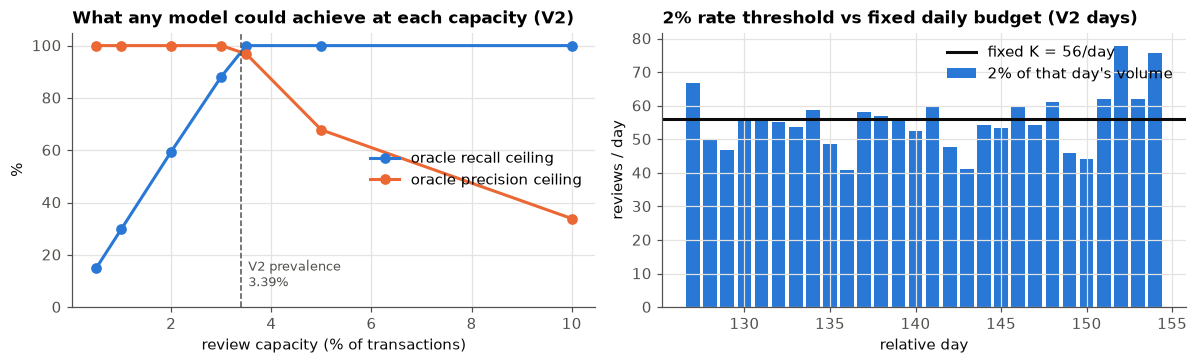

Even with a perfectly transferring 2% rate, daily workload in V2 would deviate from fixed K by -27% to +39% (SD 16%) from volume variation alone.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
x = 100 * np.array(CAPS)
ax.plot(x, 100 * cap_df["V2: oracle recall ceiling (pooled)"], color=C["blue"], marker="o", ms=6, label="oracle recall ceiling")
ax.plot(x, 100 * cap_df["oracle precision ceiling"], color=C["orange"], marker="o", ms=6, label="oracle precision ceiling")
ax.axvline(100 * pi_v2, color=C["ink2"], ls="--", lw=1)
ax.text(100 * pi_v2 + 0.15, 8, f"V2 prevalence\n{100*pi_v2:.2f}%", color=C["ink2"], fontsize=8.5)
ax.set_xlabel("review capacity (% of transactions)"); ax.set_ylabel("%"); ax.set_ylim(0, 105)
ax.set_title("What any model could achieve at each capacity (V2)"); ax.legend(loc="center right")

ax = axes[1]
K2 = int(round(0.02 * v2_mean_daily))
implied = 0.02 * v2_daily["n"]                    # reviews a perfectly-transferring 2% rate threshold would flag
ax.bar(v2_daily.index, implied, color=C["blue"], width=0.8, label="2% of that day's volume")
ax.axhline(K2, color=C["ink"], lw=2, label=f"fixed K = {K2}/day")
ax.set_title("2% rate threshold vs fixed daily budget (V2 days)")
ax.set_xlabel("relative day"); ax.set_ylabel("reviews / day"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

over = implied / K2 - 1
print(f"Even with a perfectly transferring 2% rate, daily workload in V2 would deviate from fixed K by "
      f"{100*over.min():+.0f}% to {100*over.max():+.0f}% (SD {100*over.std():.0f}%) from volume variation alone.")

**Findings [D].**
- The mean V2 day has about **2,779 transactions and 94 frauds** (range 61–136). At 1 / 2 / 5 / 10 % capacity, K ≈ **28 / 56 / 139 / 278** reviews per relative day.
- **At 2 % the budget is smaller than the number of frauds on every V2 day** (capacity/prevalence = 0.59). Even a perfect ranker could capture at most **≈ 59.5 %** of fraud (the oracle recall ceiling), while its precision could reach 100 %. At 5 % and 10 % the budget exceeds the fraud count every day. Recall can then reach 100 %, but precision is capped at 68 % and 34 %.
- A perfectly transferring 2 % *rate* threshold would still produce daily workloads between **−27 % and +39 %** of the fixed K, purely from volume variation.

**Consequences for the research design [I].**
1. **The 1/2/5/10 % grid is well placed.** It spans the *binding* regime (capacity < prevalence: 1 %, 2 %) and the *slack* regime (capacity > prevalence: 5 %, 10 %). Reporting **capacity ÷ prevalence** alongside each scenario makes results transferable to other base rates. A 3.5 % (≈ prevalence) point is optional.
2. **2 % is a defensible primary capacity**, because the binding regime is the operationally interesting one: investigators can review only a small fraction of alerts [L5, L6, L7]. But the write-up must state that **Recall@2 % has a ceiling of about 0.6**. The metric should be reported together with **normalised recall** = TP / min(K, frauds), computed daily, so readers do not mistake 0.5 for poor performance.
3. **Within a fixed-K design, Recall@K and Precision@K carry the same information.** On the same Test period both frauds (F) and K are fixed, so Precision@K = Recall@K × F / K. They must not be presented as two independent pieces of evidence.
4. **RQ3 is almost degenerate at 2 %.** A calibrated cost-aware rule leaves budget unused only when the calibrated fraud probability of the K-th ranked transaction falls below C_review / C_miss [L10]. When K is below the daily fraud count, the marginal reviewed transaction is likely to have a high fraud probability. R4 will then coincide with daily top-K (R3) for any plausible miss-to-review ratio. **RQ3 becomes informative mainly at 5 % and 10 %**, where the oracle precision ceiling itself falls to 68 % and 34 %, and at low cost ratios. RQ3 should therefore be answered across the capacity grid, with the **break-even cost ratio per capacity** as the main output, not at 2 % alone.
5. **RQ2 must separate two sources of workload error [I]:**
   - *rate fidelity*: realised alert **rate** ÷ target rate, caused by score/composition drift;
   - *budget fidelity*: realised daily **count** ÷ K, caused by rate drift × volume drift.

   Otherwise volume variation that exists regardless of the model will be attributed to "threshold transfer".

## 7. Statistical power for the confirmatory comparisons (projection, not Test data)

In [19]:
# Approximate minimum detectable paired difference in Recall@2% (McNemar / paired proportions), Test period.
# Assumptions (labelled): n_fraud = projected Test frauds; discordant share = fraction of frauds captured by
# exactly one of the two models; Holm-adjusted alpha for 3 confirmatory tests (worst case alpha/3); power 0.80.
from scipy.stats import norm
n_f = exp_test_fraud
rows = []
for disc in (0.05, 0.10, 0.20):
    for alpha, lab in ((0.05, "0.05"), (0.05 / 3, "0.0167 (Holm, 1st step)")):
        z = norm.ppf(1 - alpha / 2) + norm.ppf(0.80)
        mde = z * np.sqrt(disc / n_f)                        # delta approx for small difference relative to discordance
        rows.append({"discordant share of frauds": disc, "alpha": lab,
                     "MDE (independent frauds), pp": 100 * mde,
                     "MDE if design effect = 2, pp": 100 * mde * np.sqrt(2),
                     "MDE if design effect = 4, pp": 100 * mde * 2})
power_df = pd.DataFrame(rows)
print(f"n_fraud (projected) = {n_f:,.0f}")
power_df.round(2)

n_fraud (projected) = 2,661


,discordant share of frauds,alpha,"MDE (independent frauds), pp","MDE if design effect = 2, pp","MDE if design effect = 4, pp"
0,0.05,0.05,1.21,1.72,2.43
1,0.05,"0.0167 (Holm, 1st step)",1.40,1.98,2.80
2,0.10,0.05,1.72,2.43,3.43
3,0.10,"0.0167 (Holm, 1st step)",1.98,2.80,3.97
4,0.20,0.05,2.43,3.43,4.86
5,0.20,"0.0167 (Holm, 1st step)",2.80,3.97,5.61


**Interpretation [I].** The minimum detectable effect (MDE) is the smallest true Recall@2 % difference that a paired McNemar-type test would detect with 80 % power. It uses a normal approximation [L30, L40], a projected ~2,660 Test frauds, and assumed rates of model *disagreement* on frauds.
- With independent frauds the MDE is about **1.2–2.8 pp**.
- Frauds are **clustered** by entity (§15, about 2 frauds per pseudo-entity, with a heavy tail). A design effect of 2–4 raises the MDE to about **2–5.6 pp**.

**Implications.**
- H1 and H2 are adequately powered only for **moderate** differences. Small differences between two GBDT implementations may go undetected. The protocol must therefore declare a **smallest effect size of interest (SESOI)** before testing. For H2 in particular, a non-significant result must be read through an **equivalence test (TOST)** against that SESOI [L33], never as "no effect".
- McNemar assumes independent paired units. Because frauds cluster, the primary uncertainty should come from a **paired cluster bootstrap** (resampling pseudo-entities or days) [L31, L41, L42]. McNemar can be reported as a secondary test.
- Holm correction [L32] is appropriate for the three pre-declared confirmatory tests.

## 8. (F) Feature suitability

In [20]:
CAT_COLS = (["ProductCD"] + [f"card{i}" for i in range(1, 7)] + ["addr1", "addr2", "P_emaildomain", "R_emaildomain"]
            + [f"M{i}" for i in range(1, 10)] + [f"id_{i}" for i in range(12, 39)] + ["DeviceType", "DeviceInfo"])
feat_cols = [c for c in dev.columns if c not in ("TransactionID", "isFraud", "day", "hour_of_rel_day",
                                                 "partition", "has_identity")]
train = dev[dev["partition"] == "Train"]
v2 = dev[dev["partition"] == "V2"]

def unseen_share(col):
    seen = set(train[col].dropna().unique())
    s = v2[col].dropna()
    return 100 * (~s.isin(seen)).mean() if len(s) else np.nan

rows = []
for g in GROUP_ORDER:
    cols = [c for c in feat_cols if feature_group(c) == g]
    cats = [c for c in cols if c in CAT_COLS]
    nums = [c for c in cols if c not in CAT_COLS]
    card = train[cats].nunique() if cats else pd.Series(dtype=float)
    rows.append({
        "group": g, "n_cols": len(cols), "categorical (nominal/coded)": len(cats), "numeric": len(nums),
        "missing % (dev, mean)": dev[cols].isna().mean().mean() * 100,
        "missing % (dev, max col)": dev[cols].isna().mean().max() * 100,
        "max cardinality (Train)": int(card.max()) if len(card) else None,
        "V2 rows with category unseen in Train, % (worst col)": max((unseen_share(c) for c in cats), default=None),
    })
feat_df = pd.DataFrame(rows).set_index("group")
feat_df.round(1)

,n_cols,categorical (nominal/coded),numeric,"missing % (dev, mean)","missing % (dev, max col)",max cardinality (Train),"V2 rows with category unseen in Train, % (worst col)"
group,,,,,,,
Time,1,0,1,0.0,0.0,NaN,NaN
Amount,1,0,1,0.0,0.0,NaN,NaN
Product,1,1,0,0.0,0.0,5.0,0.0
Card,6,6,0,0.4,1.4,11870.0,1.3
Address,2,2,0,11.2,11.2,310.0,0.0
Distance,2,0,2,76.9,93.4,NaN,NaN
Email domain,2,2,0,46.1,76.5,60.0,0.0
C (counts),14,0,14,0.0,0.0,NaN,NaN
D (timedeltas),15,0,15,58.7,93.7,NaN,NaN


In [21]:
card_rows = []
for c in CAT_COLS:
    card_rows.append({"column": c, "group": feature_group(c), "dtype": str(dev[c].dtype),
                      "cardinality (Train)": train[c].nunique(), "missing % (dev)": 100 * dev[c].isna().mean(),
                      "V2 unseen-in-Train %": unseen_share(c)})
card_df = pd.DataFrame(card_rows).sort_values("cardinality (Train)", ascending=False)
print("Categorical columns with Train cardinality > 50:")
display(card_df[card_df["cardinality (Train)"] > 50].round(2).reset_index(drop=True))

# V-feature missingness blocks: columns sharing an identical missing-value mask (Train only)
vcols = [c for c in feat_cols if feature_group(c) == "V (engineered)"]
na_sig = train[vcols].isna().sum()
blocks = na_sig.groupby(na_sig).size()
print(f"V columns: {len(vcols)}; distinct missing-count signatures in Train: {len(blocks)}; "
      f"largest block: {blocks.max()} columns")
print(f"Identity coverage in development data: {100*dev['has_identity'].mean():.1f}% of transactions")

Categorical columns with Train cardinality > 50:


,column,group,dtype,cardinality (Train),missing % (dev),V2 unseen-in-Train %
0,card1,Card,int64,11870,0.00,1.34
1,DeviceInfo,Device,str,1470,79.54,3.70
2,card2,Card,float64,499,1.45,0.03
3,id_19,Identity id_01-38,float64,494,75.98,0.22
4,id_21,Identity id_01-38,float64,401,99.11,7.81
5,id_20,Identity id_01-38,float64,352,75.98,0.37
6,addr1,Address,float64,310,11.17,0.02
7,id_25,Identity id_01-38,float64,295,99.11,6.31
8,id_33,Identity id_01-38,str,166,87.31,5.09
9,card5,Card,float64,109,0.64,0.01


V columns: 339; distinct missing-count signatures in Train: 14; largest block: 46 columns
Identity coverage in development data: 24.8% of transactions


### 8.1 Feature groups — conceptual assessment

Semantics are **masked** by the organiser [L38]. Group descriptions below follow the organiser's own descriptions; anything beyond them is marked [I].

| Group | Nature | Missingness (dev) [D] | Cardinality / shift [D] | Likely usefulness | Interpretability limits | Leakage risk |
|---|---|---|---|---|---|---|
| **TransactionAmt** | numeric, USD per organiser | 0 % | continuous; KS Train→V2 = 0.013 | Weak on its own (univariate AUC ≈ 0.50 in Train) but needed for amount-weighted outcomes and interactions [I] | Clear meaning | None |
| **ProductCD** | nominal (5 levels) | 0 % | stable | Strong segmenting variable: prevalence 2 % (W) to 12.5 % (C) in V2 | Codes undisclosed | None |
| **card1–card6** | nominal (card1: 11,870 levels; card4/6 network and type) | ≤ 1.4 % | card1 high-cardinality; 1.3 % of V2 rows have unseen card1 | High; entity-like information | Masked; card1–3/5 numeric-coded nominal | **Entity memorisation** (§15) |
| **addr1, addr2** | nominal (region / country per organiser) | 11 % | 310 / 65 levels | Moderate | Masked | Entity proxy |
| **dist1, dist2** | numeric distances | 77 % | — | Uncertain; very sparse | Unknown reference points | Low |
| **P/R_emaildomain** | nominal (~60) | 16 % / 77 % | stable | Moderate | Clear meaning | Low |
| **C1–C14** | numeric counts | 0 % | — | High in practice [I] | Counting rule masked | **Unknown**: if counts include later transactions they would leak. The organiser does not state the look-back window |
| **D1–D15** | numeric time deltas | 59 % (up to 94 %) | D11 PSI 0.29 | High; also enables entity reconstruction [I] | Masked reference events | Entity proxy; ≤ 15 negative values |
| **M1–M9** | binary / ternary match flags | 52 % | PSI ≈ 0.37 Train→V2 for M1–M3, M7–M9 | Moderate | Match target undisclosed | Low |
| **V1–V339** | numeric, organiser-engineered | 43 % (up to 86 %) | 14 missingness blocks | High dimensional, heavily redundant | **Uninterpretable** | Unknown construction |
| **id_01–id_38** | mixed; 27 coded nominal | 85 % (identity only on 25 % of rows) | id_31 (browser) 40.8 % of V2 values unseen in Train | Useful but present only on a minority of rows | Mostly masked | Low; non-stationary versions |
| **DeviceType / DeviceInfo** | nominal (2 / 1,470 levels) | 78–80 % | 3.7 % unseen | Moderate | DeviceInfo is a free-text-like string | Low |

**Overall [I].** The feature space is **adequate for ranking** but poor for explanation. False-negative analysis must use the *interpretable* groups (ProductCD, card4/card6, identity presence, DeviceType, amount bands, time), not V features. Aggressive feature engineering is **unnecessary** for the RQs, which compare *decision policies and model families under a fixed feature set*. A fixed, documented, leakage-safe feature set (raw features minus `TransactionID` and raw `TransactionDT`) is the defensible choice. Any engineered aggregates must be computed with past-only windows (§16).

## 9. (G) Is LightGBM vs CatBoost a defensible model pair?

**Dataset evidence [D].** 432 raw features, including about 50 nominal columns (several of high cardinality: card1 11,870 levels, DeviceInfo 1,470), pervasive structured missingness (V/D/M/identity), and non-stationary categories (id_31).

**Literature [L].**
- Gradient-boosted decision trees remain the reference family for medium-sized heterogeneous tabular data [L15, L16].
- LightGBM [L13] handles missing values natively (learned default directions) and supports categorical splits by gradient-sorted partitioning.
- CatBoost [L14] was designed around categorical features. It uses **ordered target statistics** and **ordered boosting** specifically to avoid the *target leakage / prediction shift* that naive target encoding introduces.
- The two therefore differ on exactly the dimension this dataset stresses: high-cardinality categorical data plus missingness.

**Assessment [I].**
- **Defensible, provided the comparison is about categorical treatment and not "which library is better".** To be fair the protocol must fix: (i) the *same* column set declared categorical for both models, (ii) the *same* raw features, (iii) an *equal* tuning budget and search procedure on V1, and (iv) the same early-stopping rule. Otherwise the comparison mixes up model family with preprocessing choices.
- The contribution is **modest**. Both are GBDT implementations, and ranking differences may be small (see MDE, §7). The RQ1 result is valuable either way *if* it is framed as an estimate with a CI and an equivalence margin.
- **Do not add XGBoost, random forests or neural networks.** They would widen the study without answering any RQ.
- **L2 logistic regression as a reference baseline:** useful but optional. It gives a transparent linear floor for Recall@capacity and a contrast in calibration behaviour [L17]. It needs an imputation-and-encoding pipeline fitted on Train only, which adds engineering effort and leakage surface. **Recommendation:** include it only as a *descriptive* reference outside H1–H3, and only if time allows. The analytic **random-review baseline** (precision = prevalence) and the **oracle ceiling** (§6) are mandatory and free.

## 10. (H) Class-weighting feasibility

In [ ]:
w_rows = []
for part in ["Train", "V1", "V2"]:
    p = PI[part]
    w_rows.append({"partition": part, "prevalence %": 100 * p, "balanced positive weight (n_neg/n_pos)": (1 - p) / p,
                   "sklearn 'balanced' weights (neg, pos)": f"{0.5/(1-p):.3f}, {0.5/p:.2f}"})
pd.DataFrame(w_rows).round(2)

,partition,prevalence %,balanced positive weight (n_neg/n_pos),"sklearn 'balanced' weights (neg, pos)"
0,Train,3.39,28.53,"0.518, 14.76"
1,V1,4.22,22.68,"0.522, 11.84"
2,V2,3.39,28.51,"0.518, 14.76"


**Assessment.**
- **[D]** "Balanced" weighting implies a positive-class weight of about **28.5** (n_neg/n_pos in Train). This is a large reweighting, so the comparison is not trivial.
- **[L]** Evidence from risk-prediction research shows that imbalance corrections, including class weighting and resampling, **distort calibration** (they systematically overestimate minority-class probability). They generally do **not** improve discrimination. Where they seem to improve classification, the same effect is achieved by moving the threshold [L21, L22; L22 includes XGBoost]. Dal Pozzolo et al. [L23] show the same probability distortion for undersampling in fraud data and give a correction.
- **[I]** For a **rank-based** capacity policy (top-K), weighting can only matter if it changes the *ordering* of the top 2 %. That is possible, because weighting changes split selection in boosting, but the effect is plausibly small. H2 is therefore a genuine, testable question **whose most likely answer is "no meaningful difference"**. It must be framed with a pre-declared SESOI and an equivalence test (§7). Weighting will also shift the score scale, which directly affects R0 (fixed 0.5) and, before calibration, R4.
- **Implementation parity [I].** Use explicit per-row sample weights (w_pos = n_neg/n_pos from Train) for *both* libraries, not the libraries' own "balanced"/`is_unbalance` switches, whose internals may differ.
- **SMOTE / over- / under-sampling: not necessary, and would weaken the study.** They broaden scope, are known to harm calibration without improving ranking [L21, L22], create synthetic points with no valid timestamp (awkward in a temporal design), and SMOTE has no natural treatment for high-cardinality nominal data [L24]. The protocol's exclusion is well supported.

## 11. (I) Decision-policy feasibility (no policy is implemented here)

| Policy | Needs | Dataset support [D] | Feasibility and caveats [I] | Recommended role |
|---|---|---|---|---|
| **R0** threshold 0.5 | scores only | yes | Its alert volume is an artefact of the class weighting: few alerts for unweighted models (base rate 3.4 %), many for weighted ones. It mostly measures score scale, not policy quality. | Descriptive "naive practice" reference only; exclude from confirmatory tests [L10, L11] |
| **R1** F1-optimal threshold on V2 | V2 labels | 2,637 V2 frauds: adequate | Capacity-agnostic, so its alert count may exceed K. The protocol must say whether overflow is truncated (top-K of the flagged) or reported as a capacity violation. The F1-optimal threshold has known properties [L11]. | Secondary comparator |
| **R2** V2 rate threshold for capacity *c* | V2 scores (labels not needed) | yes; V2 volume ≈ Test volume | **Core of RQ2.** Report *rate fidelity* and *budget fidelity* separately (§6). | Core |
| **R3** daily top-K | scores, daily grouping | yes; 28 Test days, 21 V1, 28 V2 | Ranks a *whole relative day* at once, which requires end-of-day batching. It is an idealised benchmark, not a streaming policy. It is the correct policy for **H1/H2** (pure ranking quality at capacity) [L7, L8, L36, L37]. | Core; primary metric for H1/H2 |
| **R4** calibrated cost-aware, capped at K | calibrated probabilities + cost ratio | yes (calibration on V2) | Threshold is analytic, p* = C_R / C_miss [L10], so it needs no selection. At 2 % it will usually equal R3 (§6). Informative at 5 % / 10 % and low ratios. | Core for RQ3, evaluated across the capacity grid |

**Additional feasibility points.**
- **[I]** Platt and isotonic calibration are *monotone*. They leave the ranking unchanged, so R2 and R3 are **unaffected by calibration**, and R1 selects the same flagged set whether chosen on raw or calibrated scores. **Calibration matters only for R0 and R4.** This simplifies the design considerably.
- **[D]** Test has 28 relative days, so any daily-level workload statistic rests on n = 28 days.

## 12. (J, K) Cost-sensitive and calibration feasibility

In [23]:
amt_rows = []
for part in ["Train", "V1", "V2"]:
    s = dev[dev["partition"] == part]
    for lab, g in s.groupby("isFraud"):
        q = g["TransactionAmt"].quantile([0.1, 0.5, 0.9, 0.99])
        amt_rows.append({"partition": part, "class": "fraud" if lab else "legit", "n": len(g),
                         "mean": g["TransactionAmt"].mean(), "p10": q[0.1], "median": q[0.5], "p90": q[0.9],
                         "p99": q[0.99], "sum": g["TransactionAmt"].sum()})
amt_df = pd.DataFrame(amt_rows)
fr = dev[dev["isFraud"] == 1]["TransactionAmt"].sort_values(ascending=False)
top20_share = fr.iloc[: int(0.2 * len(fr))].sum() / fr.sum()
print(f"Fraud value share of development transaction value: {100 * fr.sum() / dev['TransactionAmt'].sum():.2f}% "
      f"(vs {100*dev['isFraud'].mean():.2f}% of transactions)")
print(f"Top 20% of development frauds by amount carry {100*top20_share:.1f}% of fraud value")
print(f"Fraud vs legit amount, Train, Mann-Whitney AUC = "
      f"{stats.mannwhitneyu(train.loc[train.isFraud==1,'TransactionAmt'], train.loc[train.isFraud==0,'TransactionAmt']).statistic / (train.isFraud.sum()*(train.isFraud==0).sum()):.3f}")
amt_df.round(2)

Fraud value share of development transaction value: 3.85% (vs 3.49% of transactions)
Top 20% of development frauds by amount carry 62.2% of fraud value
Fraud vs legit amount, Train, Mann-Whitney AUC = 0.502


,partition,class,n,mean,p10,median,p90,p99,sum
0,Train,legit,356148,134.22,25.95,69.00,270.66,1104.00,47800726.14
1,Train,fraud,12484,141.68,19.36,77.00,317.50,994.00,1768736.24
2,V1,legit,62776,133.77,26.95,67.95,268.00,1104.00,8397564.37
3,V1,fraud,2768,174.81,19.45,73.95,445.00,1331.00,483882.46
4,V2,legit,75185,135.09,26.95,67.95,261.95,1136.04,10156546.90
5,V2,fraud,2637,152.74,17.41,69.90,335.00,994.00,402762.72


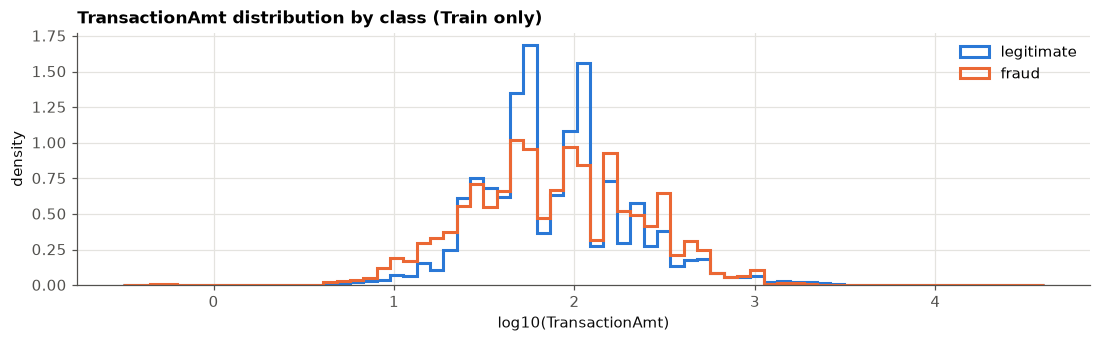

In [24]:
fig, ax = plt.subplots(figsize=(10, 3.2))
bins = np.linspace(-0.5, 4.6, 70)
for lab, col, name in ((0, C["blue"], "legitimate"), (1, C["orange"], "fraud")):
    ax.hist(np.log10(train.loc[train.isFraud == lab, "TransactionAmt"]), bins=bins, density=True,
            histtype="step", lw=2, color=col, label=name)
ax.set_xlabel("log10(TransactionAmt)"); ax.set_ylabel("density")
ax.set_title("TransactionAmt distribution by class (Train only)"); ax.legend()
plt.tight_layout(); plt.show()

**Findings [D].**
- Fraud and legitimate amount distributions **overlap almost completely** (Train Mann–Whitney AUC 0.502). Amount is not a shortcut predictor.
- Fraud value is 3.85 % of development transaction value (vs 3.49 % of transactions).
- **Fraud value is concentrated**: the top 20 % of frauds by amount carry **62 %** of fraud value. Amount-weighted recall will therefore be driven by a few hundred large frauds and will have **much wider uncertainty** than count-based recall. A bootstrap is essential.

**What the dataset can and cannot support.**

| Quantity | Status |
|---|---|
| Count of frauds captured / missed at capacity | **Dataset-supported** [D] |
| Amount-weighted recall = Σ amount of captured fraud ÷ Σ amount of fraud | **Dataset-supported** (TransactionAmt in USD per organiser [L38]) |
| "Fraud value exposed" = Σ amount of missed fraud | **Dataset-supported as a proxy** for loss exposure. Not a realised loss. |
| Review cost, false-alert/customer-friction cost, miss-to-review cost ratio | **Assumed research parameters** [I]. No such data exist in IEEE-CIS. Use a declared grid (e.g. ratios 1, 2, 5, 10, 20, 50, 100) and report **break-even ratios** [L7, L9, L44, L45]. |
| Actual chargeback losses, recovery rates, fees, the bank's true investigation cost, real analyst capacity | **Cannot be claimed.** Not in the data; the labels are chargeback-*derived* with a 120-day window [L38]. |

**Calibration [L, I].**
- R4 compares a calibrated probability with an absolute cost threshold, so it needs probabilities, not just ranks [L10, L17, L19, L20]. Calibration is therefore *necessary for R4*, but it is not a separate research question.
- Weighted models will be strongly miscalibrated by construction (weight ≈ 28.5) [L21, L22].
- **Recommendation [I]:** fit **Platt scaling** (2 parameters, stable with ~2,600 frauds [L18]) on **V2** rather than V1. Three reasons:
  1. V1 scores are early-stopping-selected.
  2. V1 prevalence (4.22 %) differs from V2 (3.39 %), a −0.23 log-odds shift (§5.1).
  3. V2 is closest in time to Test.
- Isotonic regression [L19] is a secondary check only. It is more flexible and more prone to overfitting at this sample size.
- Report the Brier score, calibration intercept and slope [L20] on V2 (in-sample for the calibrator) and on Test (confirmatory).

## 13. (L) False-negative analysis feasibility

Slice sizes are measured on **V2** and *projected* to Test by assuming the same fraud mix. No Test labels or Test false negatives are examined.

In [25]:
def amount_band(a):
    return pd.cut(a, [0, 25, 50, 100, 250, 500, np.inf], labels=["<=25", "25-50", "50-100", "100-250", "250-500", ">500"])

def slice_table(df):
    d = df.assign(identity=np.where(df["has_identity"], "present", "absent"),
                  amount_band=amount_band(df["TransactionAmt"]),
                  device=df["DeviceType"].fillna("missing"),
                  card4=df["card4"].fillna("missing"), card6=df["card6"].fillna("missing"))
    out = []
    for dim in ["identity", "ProductCD", "card4", "card6", "device", "amount_band"]:
        g = d.groupby(dim, observed=True)["isFraud"].agg(["size", "sum"])
        for lvl, r in g.iterrows():
            out.append({"slice": dim, "level": lvl, "rows": int(r["size"]), "fraud": int(r["sum"]),
                        "prevalence %": 100 * r["sum"] / r["size"]})
    return pd.DataFrame(out)

sl = slice_table(v2)
sl["share of V2 fraud %"] = 100 * sl["fraud"] / v2["isFraud"].sum()
sl["projected Test frauds"] = (sl["share of V2 fraud %"] / 100 * exp_test_fraud).round(0)
# Worst-case 95% CI half-width for a miss rate in the slice (p = 0.5) if Test mirrored V2
sl["miss-rate CI half-width (pp, worst case)"] = 100 * 1.96 * np.sqrt(0.25 / sl["projected Test frauds"].clip(lower=1))
sl["interpretable alone? (>=100 frauds)"] = np.where(sl["projected Test frauds"] >= 100, "yes", "pool / descriptive only")
sl.round(1)

,slice,level,rows,fraud,prevalence %,share of V2 fraud %,projected Test frauds,"miss-rate CI half-width (pp, worst case)",interpretable alone? (>=100 frauds)
0,identity,absent,64209,1360,2.1,51.6,1373.0,2.6,yes
1,identity,present,13613,1277,9.4,48.4,1289.0,2.7,yes
2,ProductCD,C,7729,965,12.5,36.6,974.0,3.1,yes
3,ProductCD,H,2035,120,5.9,4.6,121.0,8.9,yes
4,ProductCD,R,3053,121,4.0,4.6,122.0,8.9,yes
5,ProductCD,S,1349,102,7.6,3.9,103.0,9.7,yes
6,ProductCD,W,63656,1329,2.1,50.4,1341.0,2.7,yes
7,card4,american express,687,29,4.2,1.1,29.0,18.2,pool / descriptive only
8,card4,discover,860,119,13.8,4.5,120.0,8.9,yes
9,card4,mastercard,25437,796,3.1,30.2,803.0,3.5,yes


**Assessment.**
- **[D]** With about 2,600 Test frauds, the main interpretable slices — identity present/absent, ProductCD (C/W, with H/R/S near 100 each), card6, card4 (visa/mastercard/discover), DeviceType and amount bands — each have **≥ 100 projected frauds**. A miss-rate CI half-width is then at most about ±10 pp. `american express` (~29) and "missing" levels must be pooled or reported descriptively only.
- **[D]** Some slices differ strongly in base rate: identity present 9.4 % vs absent 2.1 %; ProductCD C 12.5 % vs W 2.1 %. Slices are therefore confounded with prevalence. **Report miss rate (FN ÷ frauds in slice) and share of all FNs, never raw FN counts alone.**
- **[I]** Useful additional slices that the data support:
  - **Recurring vs new pseudo-entity** (whether the fraud's pseudo-entity already had a Train-period fraud label, §15). This directly shows how much capacity-constrained recall comes from "recognising known bad entities".
  - **Score band.**
  - **Relative week within Test.**
- **[L, I]** Features are masked, so all FN analysis is **descriptive and non-causal**. Slices must be **pre-declared in the protocol** to avoid post-hoc subgroup mining. Multiplicity should be acknowledged, not tested.

## 14. (M) Temporal drift / distribution shift (Train → V1 → V2)

,rows/day,prevalence %,identity coverage %,fraud prevalence | identity present %,fraud prevalence | identity absent %,median amount,mean missing % (all features),mean missing % (V),mean missing % (D),mean missing % (M)
partition,,,,,,,,,,
Train,3510.78,3.39,27.10,6.83,2.11,70.00,45.11,42.74,59.86,58.00
V1,3121.14,4.22,20.67,12.08,2.18,67.95,44.81,42.63,53.80,36.42
V2,2779.36,3.39,17.49,9.38,2.12,67.95,47.03,45.13,57.34,36.23


TransactionAmt KS distance vs Train: V1 0.015, V2 0.013


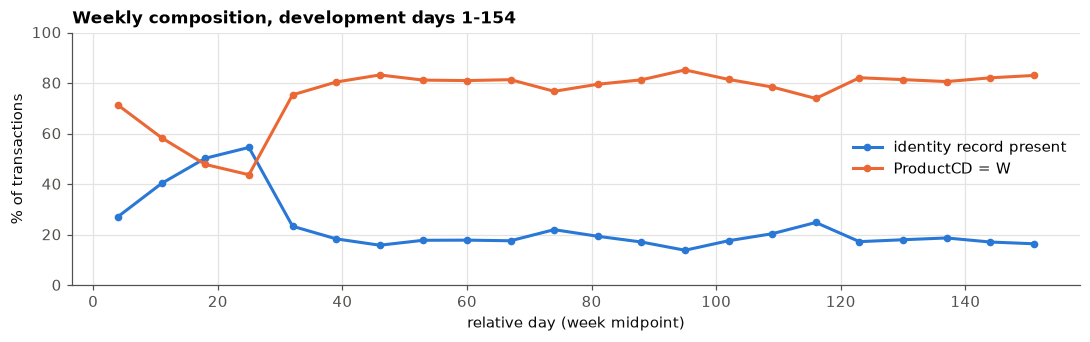

In [26]:
drift_rows = []
for part in ["Train", "V1", "V2"]:
    s = dev[dev["partition"] == part]
    days = SPLIT[part][1] - SPLIT[part][0] + 1
    drift_rows.append({
        "partition": part, "rows/day": len(s) / days, "prevalence %": 100 * s["isFraud"].mean(),
        "identity coverage %": 100 * s["has_identity"].mean(),
        "fraud prevalence | identity present %": 100 * s.loc[s.has_identity, "isFraud"].mean(),
        "fraud prevalence | identity absent %": 100 * s.loc[~s.has_identity, "isFraud"].mean(),
        "median amount": s["TransactionAmt"].median(),
        "mean missing % (all features)": 100 * s[feat_cols].isna().mean().mean(),
        "mean missing % (V)": 100 * s[vcols].isna().mean().mean(),
        "mean missing % (D)": 100 * s[[c for c in feat_cols if feature_group(c) == 'D (timedeltas)']].isna().mean().mean(),
        "mean missing % (M)": 100 * s[[c for c in feat_cols if feature_group(c) == 'M (match flags)']].isna().mean().mean(),
    })
display(pd.DataFrame(drift_rows).set_index("partition").round(2))

ks_v1 = stats.ks_2samp(train["TransactionAmt"], dev.loc[dev.partition == "V1", "TransactionAmt"]).statistic
ks_v2 = stats.ks_2samp(train["TransactionAmt"], v2["TransactionAmt"]).statistic
print(f"TransactionAmt KS distance vs Train: V1 {ks_v1:.3f}, V2 {ks_v2:.3f}")

wk = dev.assign(week=(dev["day"] - 1) // 7 + 1).groupby("week").agg(
    first_day=("day", "min"), identity=("has_identity", "mean"),
    product_W=("ProductCD", lambda s: (s == "W").mean()), missing_D=("D1", lambda s: s.isna().mean()))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(wk["first_day"] + 3, 100 * wk["identity"], color=C["blue"], marker="o", ms=4, label="identity record present")
ax.plot(wk["first_day"] + 3, 100 * wk["product_W"], color=C["orange"], marker="o", ms=4, label="ProductCD = W")
ax.set_ylim(0, 100); ax.set_xlabel("relative day (week midpoint)"); ax.set_ylabel("% of transactions")
ax.set_title("Weekly composition, development days 1-154"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

### 14.1 Feature-level drift (Population Stability Index)
PSI uses Train-decile bins for numeric features, the top-20 levels + "other" for nominal features, and an explicit "missing" bin. Conventional reading: < 0.10 small, 0.10–0.25 moderate, ≥ 0.25 large [L35]. These are heuristics, not significance tests.

In [27]:
def psi_from_counts(ref, cur, eps=1e-4):
    ref = ref / ref.sum(); cur = cur / cur.sum()
    ref, cur = ref.clip(lower=eps), cur.clip(lower=eps)
    return float(((cur - ref) * np.log(cur / ref)).sum())

def psi(col, ref_df, cur_df, n_bins=10, top_k=20):
    r, c = ref_df[col], cur_df[col]
    if col in CAT_COLS or not pd.api.types.is_numeric_dtype(r):
        top = r.value_counts().index[:top_k]
        rb = r.where(r.isin(top), "__other__").fillna("__missing__")
        cb = c.where(c.isin(top), "__other__").fillna("__missing__")
    else:
        edges = np.unique(np.nanquantile(r, np.linspace(0, 1, n_bins + 1)))
        if len(edges) < 3:
            rb, cb = r.fillna(-9e9).astype(str), c.fillna(-9e9).astype(str)
        else:
            edges[0], edges[-1] = -np.inf, np.inf
            rb = pd.cut(r, edges, include_lowest=True).astype(str).where(r.notna(), "__missing__")
            cb = pd.cut(c, edges, include_lowest=True).astype(str).where(c.notna(), "__missing__")
    levels = sorted(set(rb) | set(cb), key=str)
    return psi_from_counts(rb.value_counts().reindex(levels, fill_value=0).astype(float),
                           cb.value_counts().reindex(levels, fill_value=0).astype(float))

v1 = dev[dev["partition"] == "V1"]
psi_cols = [c for c in feat_cols if c not in ("TransactionDT",)]
psi_df = pd.DataFrame({"group": [feature_group(c) for c in psi_cols],
                       "PSI Train->V1": [psi(c, train, v1) for c in psi_cols],
                       "PSI Train->V2": [psi(c, train, v2) for c in psi_cols],
                       "PSI V1->V2": [psi(c, v1, v2) for c in psi_cols]}, index=psi_cols)
bands = pd.cut(psi_df["PSI Train->V2"], [-np.inf, 0.1, 0.25, np.inf], labels=["<0.10", "0.10-0.25", ">=0.25"])
print("Features by PSI band (Train->V2):", bands.value_counts().reindex(["<0.10", "0.10-0.25", ">=0.25"]).to_dict())
print("\nPSI >= 0.25 (Train->V2) by feature group:")
print(psi_df[psi_df["PSI Train->V2"] >= 0.25].groupby("group").size().sort_values(ascending=False).to_string())
print("\nTop 15 features by PSI Train->V2:")
psi_df.sort_values("PSI Train->V2", ascending=False).head(15).round(3)

Features by PSI band (Train->V2): {'<0.10': 396, '0.10-0.25': 23, '>=0.25': 12}

PSI >= 0.25 (Train->V2) by feature group:
group
M (match flags)      6
V (engineered)       3
Identity id_01-38    2
D (timedeltas)       1

Top 15 features by PSI Train->V2:


,group,PSI Train->V1,PSI Train->V2,PSI V1->V2
id_31,Identity id_01-38,0.649,0.701,0.058
id_13,Identity id_01-38,0.531,0.663,0.285
M3,M (match flags),0.317,0.376,0.003
M2,M (match flags),0.317,0.375,0.003
M1,M (match flags),0.316,0.375,0.003
M9,M (match flags),0.419,0.367,0.002
M8,M (match flags),0.418,0.367,0.002
M7,M (match flags),0.418,0.367,0.002
D11,D (timedeltas),0.353,0.288,0.015
V3,V (engineered),0.337,0.250,0.008


**Findings [D].**
- **Volume** falls from 3,511 (Train) to 2,779 (V2) rows/day (−21 %).
- **Prevalence** is 3.39 → 4.22 → 3.39 %: episodic, not trending (§5.1).
- **Identity coverage falls sharply**: 27.1 % → 20.7 % → 17.5 %. At the same time, fraud prevalence *among* identity-present rows rises from 6.8 % to 9.4–12.1 %, while identity-absent prevalence stays flat at about 2.1 %. **[I]** The overall fraud rate looks stable, but it is a mixture whose parts are changing. A threshold tuned on one mixture may transfer poorly. This is precisely the mechanism RQ2 is meant to measure, and it is measurable here.
- **Amount distribution is stable** (KS 0.013–0.015): negligible.
- **Feature drift**: 396 of 431 features have PSI < 0.10 Train→V2; 23 are moderate; **12 are large**. The large ones are M1–M3 and M7–M9 (≈ 0.37), the V1–V11 block (0.25), D11 (0.29), id_31 (browser version, 0.70) and id_13 (0.66). **[D]** M-flag missingness falls from **58 % in Train to 36 % in V1 and V2**, and D missingness moves 59.9 → 53.8 → 57.3 %. **[I]** The large M, D11 and V1–V11 PSI values are therefore mostly changes in *which fields are populated*, most likely in data collection, rather than evidence of changed fraud behaviour. They are more likely changes in data *collection* than in fraud behaviour. id_31 drift reflects new browser versions: 40.8 % of V2 values are unseen in Train. This is realistic non-stationarity.
- **V1 → V2 PSI is small for almost all features.** Most shift happens between Train and the validation periods, not between V1 and V2.

**Interpretation limits.** With 65–370k rows per partition every difference is statistically significant. Only effect sizes (PSI, KS, pp differences, log-odds shifts) are interpreted, and only the large ones are called material.

## 15. Entity recurrence and label dependence (development data only)

The organiser states that a reported chargeback marks the card's transaction as fraud, **and that later transactions linked to the same user account, email address or billing address are also labelled fraud** [L38]. If so, fraud labels are *not independent across transactions*. The check below uses two **heuristic** pseudo-entity keys. Neither is a verified identifier; the "fine" key's use of `day − D1` as an account-start proxy is an inference.

In [28]:
# Two HEURISTIC pseudo-entity keys (neither is a verified card/customer identifier):
#   coarse: card attributes + billing region
#   fine  : card1 + addr1 + purchaser email domain + implied reference day (relative day - D1)
# D1 is an anonymised timedelta; using (day - D1) as an "account start" proxy is an inference, not documented fact.
def pseudo_key(df, cols):
    return df[cols].astype("string").fillna("NA").agg("|".join, axis=1)

dev["start_proxy"] = (dev["day"] - dev["D1"]).round()
KEYS = {"coarse": ["card1", "card2", "card3", "card5", "addr1"],
        "fine": ["card1", "addr1", "P_emaildomain", "start_proxy"]}
ent_rows = {}
for name, cols in KEYS.items():
    k = pseudo_key(dev, cols)
    tr_k, tr_f = set(k[dev.partition == "Train"]), set(k[(dev.partition == "Train") & (dev.isFraud == 1)])
    m2 = (dev.partition == "V2").to_numpy()
    kv, yv = k[m2], dev.loc[m2, "isFraud"]
    seen, fseen = kv.isin(tr_k), kv.isin(tr_f)
    fr_per_key = kv[yv == 1].value_counts()
    ent_rows[name] = {
        "distinct keys in Train": len(tr_k),
        "V2 transactions with key seen in Train (%)": 100 * seen.mean(),
        "V2 frauds with key seen in Train (%)": 100 * seen[yv == 1].mean(),
        "V2 frauds whose key had >=1 Train fraud (%)": 100 * fseen[yv == 1].mean(),
        "V2 prevalence | key had Train fraud (%)": 100 * yv[fseen].mean(),
        "V2 prevalence | key seen, no Train fraud (%)": 100 * yv[seen & ~fseen].mean(),
        "V2 prevalence | key not seen in Train (%)": 100 * yv[~seen].mean(),
        "V2 frauds per fraudulent key (mean)": fr_per_key.mean(),
        "upper-bound design effect for fraud-level recall (sum m^2 / sum m)": (fr_per_key**2).sum() / fr_per_key.sum(),
    }
    if name == "fine":
        dev["fine_key"] = k
ent = pd.DataFrame(ent_rows)

# Duplicate feature rows within development data: do identical feature vectors carry conflicting labels?
dcols = [c for c in feat_cols if c not in ("TransactionDT",)]
row_hash = pd.util.hash_pandas_object(dev[dcols], index=False)
g = dev.groupby(row_hash)["isFraud"].agg(["size", "nunique"])
print(f"Development feature-duplicate groups (ignoring TransactionDT): {int((g['size'] > 1).sum())}; "
      f"groups with conflicting labels: {int((g['nunique'] > 1).sum())}")
ent.round(2)

Development feature-duplicate groups (ignoring TransactionDT): 332; groups with conflicting labels: 5


,coarse,fine
distinct keys in Train,35430.00,188563.00
V2 transactions with key seen in Train (%),94.14,34.93
V2 frauds with key seen in Train (%),91.77,17.48
V2 frauds whose key had >=1 Train fraud (%),70.46,16.88
V2 prevalence | key had Train fraud (%),5.07,68.36
"V2 prevalence | key seen, no Train fraud (%)",1.54,0.06
V2 prevalence | key not seen in Train (%),4.76,4.30
V2 frauds per fraudulent key (mean),3.59,1.95
upper-bound design effect for fraud-level recall (sum m^2 / sum m),15.19,4.25


**Findings [D].**
- **Coarse key** (card attributes + region): 94 % of V2 rows have a key seen in Train. The key is too broad to identify entities: prevalence given a Train-fraud key is only 5.1 %.
- **Fine key:** **16.9 % of V2 frauds belong to a pseudo-entity that already had a fraud label in Train.** Among V2 transactions from such entities, prevalence is **68 %**, against **0.06 %** for entities seen in Train without fraud and 4.3 % for entities never seen. V2 frauds average about **2 per fraudulent pseudo-entity**, with a heavy tail. The upper-bound design effect for fraud-level recall is about **4.3**, which is why §7 brackets design effects of 2–4.
- Only 5 groups of identical feature vectors in the development data carry conflicting labels. Label noise from duplicates is negligible.

**Implications [I].**
1. **Random or shuffled splits would be seriously optimistic.** Linked transactions would appear on both sides. The chronological design is necessary, not optional [L28, L29].
2. **Even a temporal split lets a model "recognise" previously labelled entities.** That is realistic *only if* those labels would have been known at scoring time. The dataset has **no label-report dates**, so label latency cannot be simulated faithfully [L6]. This is an **unavoidable optimism bias**. It must be stated as a threat to validity and quantified through the recurring-vs-new FN slice.
3. **Frauds are clustered.** Transaction-level bootstrap and McNemar understate uncertainty, so use a cluster (pseudo-entity) or day-block bootstrap [L41, L42] (§7).
4. **Capacity is counted per transaction.** In practice, reviewing one transaction of a compromised account typically triggers action on the whole account. A transaction-level K therefore *overstates* the review effort needed to stop entity-level fraud. This is a construct-validity limitation to acknowledge. Card-level precision metrics exist in the fraud literature [L8], but IEEE-CIS has no true card ID.

## 16. (N) Leakage audit

| # | Risk | Why it matters | Severity | Proposed control |
|---|---|---|---|---|
| 1 | **Random / shuffled splitting** | Label propagation across linked transactions [L38] plus entity recurrence (§15) inflate every metric [L28, L29] | **High** | Chronological, day-aligned split only (frozen here). No k-fold CV across time. Tuning on V1 holdout. |
| 2 | **Test-informed design** | Choosing features, policies, capacities or cost ratios after seeing Test results invalidates confirmatory claims | **High** | Test sealed in this notebook; protocol freeze and Git tag before one-shot Test run; Test-access log |
| 3 | **Future-data aggregates** (frequency/count encodings, entity aggregates computed over all 182 days) | Leaks Test-period volume and entity behaviour into Train features | **High** | Fit any encoding/aggregate on Train only, or with past-only (expanding) windows. Prefer raw features. |
| 4 | **Entity memorisation / label propagation** | A model recognises entities already labelled fraud, which is realistic only if labels were available in time | **High, not fully controllable** | Report the recurring-vs-new pseudo-entity slice; state as a threat to validity; do not engineer entity IDs (e.g. `card1+addr1+D1` keys) *as features* in the primary design |
| 5 | **`TransactionID` / raw `TransactionDT` as features** | Both encode absolute time. Trees cannot extrapolate, and the IDs act as time stamps. | Medium | Exclude both. Hour-of-day from `TransactionDT` is optional and past-safe. |
| 6 | **Categorical-encoding leakage** | Naive target encoding uses the row's own label [L14] | Medium | Native categorical handling only (CatBoost ordered TS; LightGBM categorical splits). No manual target encoding. |
| 7 | **Preprocessing leakage** (imputers/scalers/encoders for the LR baseline) | Statistics from V1/V2/Test enter Train | Medium | Fit pipelines on Train only |
| 8 | **Threshold / calibration selected on selected-on data** | Early stopping on V1 makes V1 scores optimistic | Medium | Early stopping and tuning on V1; calibration and threshold selection on V2 |
| 9 | **Capacity K derived from Test volume** | Uses future volume to set the budget | Medium | K = c × mean V2 daily volume, fixed before Test |
| 10 | **Retrospective (mature) labels** | All labels resolved with a 120-day window [L38]; deployment has label latency [L6] | Medium | Cannot be fixed. Latency sensitivity using V2 days 127–147 for label-dependent choices; acknowledge. |
| 11 | **Unknown construction of C / D / V features** | Organiser-engineered; look-back windows undocumented. A forward-looking count would leak. | Unknown | Cannot verify. Acknowledge. Drift and missingness evidence gives no sign of forward-looking construction, but absence of evidence is not proof. |
| 12 | **Class weights computed beyond Train** | Uses validation/Test prevalence | Low | w_pos from Train counts only |
| 13 | **Duplicate / near-duplicate rows across partitions** | Same record on both sides | Low | 3 fully identical feature rows in the whole dataset; negligible |

## 17. (O) MSc research suitability — critical assessment

**1. Can the dataset support the main research question?** **Yes, with changes.** It has labelled, time-ordered transactions over 182 relative days, enough volume for daily budgets (§6), measurable drift in the composition that drives threshold transfer (§14), and amounts for value-weighted outcomes. What it lacks — real costs, real capacity, label-report dates, entity IDs, calendar time — limits *how* the question can be answered, not *whether*.

**2. Can it support all three RQs?**
- **RQ1: yes.** About 2,600 projected Test frauds support Recall@2 % comparisons, but only for moderate effects (MDE ≈ 1.2–5.6 pp depending on disagreement and clustering). Needs a declared SESOI and equivalence framing for H2.
- **RQ2: yes, but weakly identified as currently written.** (a) There is only one V2→Test transfer event. (b) Daily volume variation alone moves workload −27 % to +39 %. (c) H3 as a point null ("preserves workload") will almost certainly be rejected at this sample size, which makes it uninformative. RQ2 needs rate-vs-budget decomposition, a pre-declared tolerance band and the rolling-origin supplement.
- **RQ3: partially.** Costs are assumed, which is acceptable if framed as scenario and break-even analysis. But at the 2 % primary capacity, R4 will usually coincide with R3 (§6). RQ3 is informative mainly at 5–10 % capacity and must be answered across the capacity grid.

**3. Is it deep enough for a Greenwich MSc Data Science project?** **Yes, if the depth comes from the evaluation design rather than model count.** That means the pre-registered temporal protocol, the capacity/prevalence regimes, the workload-fidelity decomposition, the cluster-aware uncertainty and the break-even analysis. The public course page describes "a substantial MSc project where you apply your knowledge to a real-world challenge" [G5]. The COMP1885 marking criteria were not accessible and must be checked. **[I]** A tightly controlled evaluation study fits that description; a model leaderboard would be a weaker fit.

**4. Is it research rather than model engineering?** It is at risk. H1 and H2 are, taken alone, model-engineering comparisons. The research contribution lies in **RQ2 and RQ3**, which concern how validation-time decisions behave under temporal shift and capacity limits. **Novelty must not be claimed for:** capacity-constrained evaluation (Hand et al. 2008 [L7]; alert-precision@k in Dal Pozzolo et al. [L5, L6]; Le Borgne et al. [L8]); temporal evaluation of IEEE-CIS (chronological out-of-time evaluations of this dataset already exist [L46, L47]); or cost-sensitive thresholding [L9, L10]. A defensible framing is *"a controlled, pre-registered, uncertainty-quantified evaluation of how score-to-review policies transfer across time under fixed review capacity on a public benchmark"*.

**5. Enough temporal information?** **Adequate for one confirmatory holdout** (4 weeks) plus a 3-way development split and a small rolling-origin supplement. Not enough to study seasonality, long-horizon drift or retraining schedules. There is no calendar, so no seasonal claims.

**6. Is capacity analysis meaningful?** **Yes.** Daily volume (~2,800) and fraud counts (~94/day) give non-trivial K at every scenario, and the 1/2/5/10 % grid spans binding and slack regimes. All capacities are simulated.

**7. Is cost analysis defensible?** **Only as a sensitivity / break-even analysis with assumed ratios.** Amount-weighted recall and fraud value exposed are data-supported. Monetary "savings" are not.

**8. Are LightGBM and CatBoost a defensible pair?** **Yes, narrowly**, as a test of categorical/missing-value treatment on high-cardinality tabular data, with strict parity controls (§9). Expect small differences.

**9. Biggest methodological weaknesses.**
1. Entity-level label dependence plus missing label-report dates: unavoidable optimism, and it needs cluster-aware inference (§15).
2. A single confirmatory transfer event for RQ2.
3. Limited power for small model/weighting effects.
4. RQ3 near-degenerate at 2 %.
5. Masked features: FN analysis is shallow and descriptive only.
6. Transaction-level capacity versus entity-level operations.
7. Assumed costs.

**10. Parts of the current design the dataset does not support.**
- The "severe class imbalance" description (§5).
- H3 as a point null.
- Any claim of real institutional costs or capacities.
- Any calendar or seasonal interpretation.
- Calibration fitted on V1 (poorly supported by the V1 prevalence shift and V1's role in early stopping).
- Treating Recall@2 % and Precision@2 % as independent evidence.
- Answering RQ3 at 2 % capacity alone.

## 18. (P) Comparison with international research practice

| Area | Strong current practice [L] | Current design | Gap → action [I] |
|---|---|---|---|
| Fraud evaluation under investigator limits | Evaluate detection at a fixed number of investigations or alerts; top-k / alert precision; card-level metrics [L5–L8] | Recall@capacity with daily K | Aligned. Add normalised recall and the oracle ceiling; acknowledge transaction- vs entity-level counting |
| Temporal validation | Chronological or prequential evaluation; concept drift and verification latency [L6, L8, L25] | Train/V1/V2/Test chronological | Aligned. Add a small rolling-origin supplement for RQ2; latency sensitivity |
| Imbalanced evaluation metrics | PR-based and threshold-aware metrics rather than accuracy/ROC alone [L1, L12] | AP, ROC-AUC secondary | Aligned |
| Imbalance treatment | Prefer threshold choice and cost-sensitive decisions over resampling; watch calibration [L21–L23] | Unweighted vs balanced weights; no resampling | Aligned. Add a SESOI and equivalence test for H2 |
| Decision thresholds | Thresholds chosen on held-out data; cost-derived thresholds need calibrated probabilities [L10, L11, L43] | R0–R4 on V2 | Mostly aligned. Move calibration to V2; R4 threshold analytic |
| Cost uncertainty | Evaluate across cost ranges, cost curves, break-even analysis [L44, L45] | Scenario ratios | Aligned if break-even ratios are the headline output |
| Statistical uncertainty | Paired tests, bootstrap CIs, multiplicity control; clustered data need cluster resampling [L30–L33, L41, L42] | Paired bootstrap, McNemar, Holm | Add cluster/day-block bootstrap; equivalence testing |
| Leakage & reproducibility | Explicit leakage taxonomy; pre-registration; frozen splits [L28, L29] | Planned protocol freeze | This notebook provides the split hash and pre-freeze access log |

## 19. (Q) University of Greenwich alignment

| Topic | University requirement [G] | General research best practice [L] | Recommendation [I] |
|---|---|---|---|
| **Scope of ethics policy** | The Research Ethics Policy applies to all research by "master's students in connection with their programmes of study" (§1.2) [G1] | — | The project is in scope; the ethics route must be documented |
| **Secondary, anonymised data** | "Indirect involvement through access to non-anonymised personal information" counts as human participation (§1.3.1 iii) [G1]. If data are fully anonymised "you shouldn't need ethical approval" [G2] | Assess re-identification risk even for "anonymised" data | IEEE-CIS is masked/anonymised by the provider [L38]. Record this reasoning in the ethics form |
| **Sensitive / criminal subject matter** | Research "involving harmful, criminal, particularly sensitive … subject matters" requires ethical consideration (§1.3.4) and is categorised **Higher Risk** (§2.2.1 iv) [G1]. Higher-Risk student projects go to UREB after FREC review (§2.4) unless delegated (§2.5.2) | — | **Unresolved and important.** Fraud is criminal subject matter. Whether analysis of an anonymised public fraud benchmark falls under §1.3.4 is a judgement for the module leader / FREC. **Obtain written confirmation of the route before confirmatory experiments.** |
| **Who advises taught students** | Taught students "should be advised by your programme/module leader whether ethical approval is required … and the appropriate faculty committee" [G2]; FRECs handle taught-postgraduate projects (§2.3a) [G1] | — | Ask the supervisor/module leader explicitly; keep the reply |
| **Data handling** | Data stored securely; mobile devices used to store data must be encrypted [G2] | Record checksums and provenance | Keep raw data out of Git (already in `.gitignore`); use an encrypted device; record the SHA-256 values above in the dataset manifest |
| **Data licence / terms** | — | Respect the provider's terms of use | **Verify the Kaggle competition rules** for permitted academic use and redistribution (not checked here: the rules page requires login). Do not redistribute raw data. |
| **Research integrity** | The University follows the Concordat to Support Research Integrity (2025) [G3] | Transparent reporting, pre-registration, honest negative results | Tag the frozen protocol in Git before the Test run; report null results |
| **AI use** | Students must acknowledge AI use with an **"AI Reflection (AIR)"** at the end of assessed work. Assessments are Tier 1 (independent of AI), Tier 2 (supported by AI) or Tier 3 (augmented with AI) [G4] | Disclose AI assistance; verify AI-generated content | **This notebook was produced with AI assistance.** Check the COMP1885 assessment's tier, declare this use in the AIR, and independently verify its code, numbers and citations |
| **COMP1885 module specifics** | The public course page states only that the project is "a substantial MSc project where you apply your knowledge to a real-world challenge" [G5]. **The COMP1885 handbook, marking scheme and word limits were not publicly accessible.** | — | Check the module handbook (Moodle) for required dissertation structure, ethics form deadlines and marking criteria before protocol freeze |

---
## Dataset Feasibility Decision

### **Decision: Suitable with methodological changes**

**Why.** The IEEE-CIS labelled data are clean at the structural level: unique keys, a one-to-one join, negligible duplication and complete labels [D]. They are time-ordered over 182 relative days [D] and large enough to give non-trivial daily review budgets and about 2,600 projected Test frauds [D]. They also show real, measurable composition drift (identity coverage 27 % → 17.5 %; episodic prevalence 2–5 % weekly) that makes threshold transfer a meaningful object of study [D]. The main RQ and RQ1 are supported as designed.

**Changes are needed** because the audit found that:
1. RQ2/H3 as currently written confound volume drift with score drift and pose an untestable point null.
2. RQ3 is nearly degenerate at the 2 % primary capacity, because capacity is below prevalence on every day.
3. Fraud labels are entity-dependent, so transaction-level inference is anti-conservative.
4. The planned calibration on V1 conflicts with V1's early-stopping role and its shifted prevalence.
5. The imbalance terminology overstates the problem.

None of these makes the dataset unsuitable; each needs a protocol change.

### Recommended final research scope
- **Keep** the main RQ and RQ1 wording.
- **RQ2:** reword to *"…how accurately do validation-selected thresholds preserve the intended review **rate** and the fixed daily review **budget**, and how much fraud is missed as a result?"* Replace H3's point null with a **tolerance hypothesis**, e.g. H3₀: the realised Test alert rate lies within ±X % (relative) of the 2 % target (X declared before freeze). Report budget fidelity descriptively. Add a development-only rolling-origin supplement (exploratory).
- **RQ3:** answer across the **capacity grid**, with **break-even miss-to-review cost ratios** per capacity as the main output. State in advance that R4 ≈ R3 is expected at 2 %.
- **Out of scope:** new model families, resampling, feature-engineering studies, real monetary claims, causal FN claims.

### Recommended dataset split structure
| Partition | Relative days | Days | Rows | Role |
|---|---|---|---|---|
| Train | 1–105 | 105 | 368,632 (62.4 %) | Model fitting (no refit later) |
| V1 | 106–126 | 21 | 65,544 (11.1 %) | Hyper-parameter selection and early stopping only |
| V2 | 127–154 | 28 | 77,822 (13.2 %) | Calibration (Platt), R1/R2 threshold selection, K from mean V2 volume |
| Gap | — | 0 | — | None in the primary design; latency sensitivity uses V2 days 127–147 for label-dependent choices |
| Test | 155–182 | 28 | 78,542 (13.3 %) | One confirmatory evaluation |

Partition hashes are in §4.3.

### Recommended primary metric
**Recall@2 % daily capacity under R3 (daily top-K, K = 56 per relative day)**, pooled over the 28 Test days, for H1/H2. Report it together with:
- normalised recall (TP / min(K, frauds), daily);
- the oracle ceiling (≈ 0.6 at 2 %).

Precision@2 % is a rescaling of the same quantity, not separate evidence. Secondary: AP (PR-AUC), amount-weighted recall, and Brier/calibration for R4.

### Recommended review-capacity scenario
**2 % primary** (binding regime, capacity/prevalence ≈ 0.6). **1 %, 5 % and 10 % secondary**, each reported with its capacity ÷ prevalence ratio. K is fixed per relative day from V2 volume (28 / 56 / 139 / 278). All scenarios are described as simulated.

### Recommended model scope
- LightGBM and CatBoost with identical raw features (excluding `TransactionID` and raw `TransactionDT`), an identical declared categorical set, equal tuning budgets on V1, and the same early-stopping rule.
- L2 logistic regression optional and descriptive only.
- Random-review and oracle baselines computed analytically.

### Recommended imbalance treatment
- Unweighted vs balanced weighting, implemented as explicit sample weights with w_pos = n_neg/n_pos from Train (≈ 28.5) for both libraries.
- No SMOTE, over-sampling or under-sampling.
- H2 tested with a pre-declared SESOI and TOST equivalence.

### Recommended decision-policy scope
- **Core:** R2 (rate threshold, RQ2), R3 (daily top-K, H1/H2), R4 (calibrated cost-aware capped, RQ3 across the capacity grid, analytic threshold C_R/C_miss).
- **Secondary:** R1 (F1-optimal, with a pre-declared overflow rule).
- **Descriptive only:** R0 (0.5).

### Key threats to validity
- **Internal:**
  - entity-level label dependence and retrospective labels (optimism; §15);
  - organiser-engineered features of unknown construction;
  - limited power for small effects.
- **Construct:**
  - transaction-level review counting vs entity-level operations;
  - "capacity" and "cost" are simulated;
  - labels are chargeback-derived and miss unreported fraud [L38].
- **Statistical conclusion:**
  - clustered frauds (use cluster/day-block bootstrap);
  - only 28 Test days for daily statistics;
  - one transfer event for RQ2.
- **External:** one anonymised e-commerce provider over ~6 months; relative time only; results may not transfer to other institutions, channels or fraud mixes.

### Required changes before protocol freeze
1. Replace "severe class imbalance" with "imbalanced (≈ 28 : 1), low-prevalence" in the documentation.
2. Freeze split A (days 1–105 / 106–126 / 127–154 / 155–182) with the partition hashes from §4.3.
3. Move calibration from V1 to V2. Define R4's threshold analytically as C_R/C_miss. State that calibration does not affect R1–R3.
4. Rewrite H3 with a declared tolerance band. Separate rate fidelity from budget fidelity.
5. Declare SESOIs for H1 and H2; add TOST for H2.
6. Specify cluster-aware uncertainty (pseudo-entity or day-block paired bootstrap) as primary; McNemar as secondary.
7. Re-scope RQ3 to the capacity grid, with break-even ratios as the main output. Declare the cost-ratio grid.
8. Define K = round(c × mean V2 daily volume), and the overflow rule for R1/R2.
9. Fix the feature set: drop `TransactionID` and raw `TransactionDT`; list the categorical columns declared for both libraries; no future-looking aggregates; no manual target encoding.
10. Pre-declare FN slices, including recurring-vs-new pseudo-entity, and the ≥ 100-fraud interpretability rule.
11. Add the development-only rolling-origin supplement for RQ2 (exploratory).
12. Resolve the Greenwich ethics route in writing (criminal-subject-matter clause, §1.3.4 of the Research Ethics Policy) and verify the Kaggle data-use terms.
13. Revise the novelty statement: no novelty claim for capacity-constrained or temporal evaluation per se.

## References

**Literature and methodological sources [L]**

1. He, H. & Garcia, E.A. (2009) 'Learning from imbalanced data', *IEEE Transactions on Knowledge and Data Engineering*, 21(9), pp. 1263–1284. doi:10.1109/TKDE.2008.239
2. Leevy, J.L., Khoshgoftaar, T.M., Bauder, R.A. & Seliya, N. (2018) 'A survey on addressing high-class imbalance in big data', *Journal of Big Data*, 5, 42. doi:10.1186/s40537-018-0151-6
3. Krawczyk, B. (2016) 'Learning from imbalanced data: open challenges and future directions', *Progress in Artificial Intelligence*, 5(4), pp. 221–232. doi:10.1007/s13748-016-0094-0
4. Fernández, A., García, S., Galar, M., Prati, R.C., Krawczyk, B. & Herrera, F. (2018) *Learning from Imbalanced Data Sets*. Cham: Springer. doi:10.1007/978-3-319-98074-4
5. Dal Pozzolo, A., Caelen, O., Le Borgne, Y.-A., Waterschoot, S. & Bontempi, G. (2014) 'Learned lessons in credit card fraud detection from a practitioner perspective', *Expert Systems with Applications*, 41(10), pp. 4915–4928. doi:10.1016/j.eswa.2014.02.026
6. Dal Pozzolo, A., Boracchi, G., Caelen, O., Alippi, C. & Bontempi, G. (2018) 'Credit card fraud detection: a realistic modeling and a novel learning strategy', *IEEE Transactions on Neural Networks and Learning Systems*, 29(8), pp. 3784–3797. doi:10.1109/TNNLS.2017.2736643
7. Hand, D.J., Whitrow, C., Adams, N.M., Juszczak, P. & Weston, D. (2008) 'Performance criteria for plastic card fraud detection tools', *Journal of the Operational Research Society*, 59(7), pp. 956–962. doi:10.1057/palgrave.jors.2602418
8. Le Borgne, Y.-A., Siblini, W., Lebichot, B. & Bontempi, G. (2022) *Reproducible Machine Learning for Credit Card Fraud Detection — Practical Handbook*. Université Libre de Bruxelles. https://fraud-detection-handbook.github.io/fraud-detection-handbook/ (open handbook; not peer-reviewed; chapters on top-k metrics and prequential validation with train/delay/test periods)
9. Bahnsen, A.C., Aouada, D., Stojanovic, A. & Ottersten, B. (2016) 'Feature engineering strategies for credit card fraud detection', *Expert Systems with Applications*, 51, pp. 134–142. doi:10.1016/j.eswa.2015.12.030
10. Elkan, C. (2001) 'The foundations of cost-sensitive learning', *Proceedings of IJCAI 2001*, pp. 973–978.
11. Lipton, Z.C., Elkan, C. & Naryanaswamy, B. (2014) 'Optimal thresholding of classifiers to maximize F1 measure', *ECML PKDD 2014*, LNCS 8725, pp. 225–239. doi:10.1007/978-3-662-44851-9_15
12. Saito, T. & Rehmsmeier, M. (2015) 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, 10(3), e0118432. doi:10.1371/journal.pone.0118432
13. Ke, G. et al. (2017) 'LightGBM: a highly efficient gradient boosting decision tree', *Advances in Neural Information Processing Systems 30*.
14. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A.V. & Gulin, A. (2018) 'CatBoost: unbiased boosting with categorical features', *Advances in Neural Information Processing Systems 31*.
15. Grinsztajn, L., Oyallon, E. & Varoquaux, G. (2022) 'Why do tree-based models still outperform deep learning on typical tabular data?', *NeurIPS 35, Datasets and Benchmarks Track*.
16. Shwartz-Ziv, R. & Armon, A. (2022) 'Tabular data: deep learning is not all you need', *Information Fusion*, 81, pp. 84–90. doi:10.1016/j.inffus.2021.11.011
17. Niculescu-Mizil, A. & Caruana, R. (2005) 'Predicting good probabilities with supervised learning', *Proceedings of ICML 2005*, pp. 625–632.
18. Platt, J. (1999) 'Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods', in *Advances in Large Margin Classifiers*. MIT Press, pp. 61–74.
19. Zadrozny, B. & Elkan, C. (2002) 'Transforming classifier scores into accurate multiclass probability estimates', *Proceedings of KDD 2002*, pp. 694–699.
20. Van Calster, B., McLernon, D.J., van Smeden, M., Wynants, L. & Steyerberg, E.W. (2019) 'Calibration: the Achilles heel of predictive analytics', *BMC Medicine*, 17, 230. doi:10.1186/s12916-019-1466-7
21. van den Goorbergh, R., van Smeden, M., Timmerman, D. & Van Calster, B. (2022) 'The harm of class imbalance corrections for risk prediction models: illustration and simulation using logistic regression', *Journal of the American Medical Informatics Association*, 29(9), pp. 1525–1534. doi:10.1093/jamia/ocac093
22. Carriero, A., Luijken, K., de Hond, A., Moons, K.G.M., van Calster, B. & van Smeden, M. (2025) 'The harms of class imbalance corrections for machine learning based prediction models: a simulation study', *Statistics in Medicine*, 44(3–4), e10320. doi:10.1002/sim.10320
23. Dal Pozzolo, A., Caelen, O., Johnson, R.A. & Bontempi, G. (2015) 'Calibrating probability with undersampling for unbalanced classification', *IEEE Symposium Series on Computational Intelligence (SSCI)*, pp. 159–166.
24. Chawla, N.V., Bowyer, K.W., Hall, L.O. & Kegelmeyer, W.P. (2002) 'SMOTE: synthetic minority over-sampling technique', *Journal of Artificial Intelligence Research*, 16, pp. 321–357.
25. Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M. & Bouchachia, A. (2014) 'A survey on concept drift adaptation', *ACM Computing Surveys*, 46(4), 44. doi:10.1145/2523813
26. Tashman, L.J. (2000) 'Out-of-sample tests of forecasting accuracy: an analysis and review', *International Journal of Forecasting*, 16(4), pp. 437–450.
27. Cerqueira, V., Torgo, L. & Mozetič, I. (2020) 'Evaluating time series forecasting models: an empirical study on performance estimation methods', *Machine Learning*, 109, pp. 1997–2028. doi:10.1007/s10994-020-05910-7
28. Kaufman, S., Rosset, S., Perlich, C. & Stitelman, O. (2012) 'Leakage in data mining: formulation, detection, and avoidance', *ACM Transactions on Knowledge Discovery from Data*, 6(4), 15. doi:10.1145/2382577.2382579
29. Kapoor, S. & Narayanan, A. (2023) 'Leakage and the reproducibility crisis in machine-learning-based science', *Patterns*, 4(9), 100804. doi:10.1016/j.patter.2023.100804
30. Dietterich, T.G. (1998) 'Approximate statistical tests for comparing supervised classification learning algorithms', *Neural Computation*, 10(7), pp. 1895–1923.
31. Efron, B. & Tibshirani, R.J. (1993) *An Introduction to the Bootstrap*. New York: Chapman & Hall.
32. Holm, S. (1979) 'A simple sequentially rejective multiple test procedure', *Scandinavian Journal of Statistics*, 6(2), pp. 65–70.
33. Lakens, D. (2017) 'Equivalence tests: a practical primer for t tests, correlations, and meta-analyses', *Social Psychological and Personality Science*, 8(4), pp. 355–362. doi:10.1177/1948550617697177
34. Rabanser, S., Günnemann, S. & Lipton, Z.C. (2019) 'Failing loudly: an empirical study of methods for detecting dataset shift', *Advances in Neural Information Processing Systems 32*.
35. Siddiqi, N. (2006) *Credit Risk Scorecards: Developing and Implementing Intelligent Credit Scoring*. Hoboken, NJ: Wiley. (Source of the conventional PSI bands, which are practitioner heuristics.)
36. Rodolfa, K.T., Lamba, H. & Ghani, R. (2021) 'Empirical observation of negligible fairness–accuracy trade-offs in machine learning for public policy', *Nature Machine Intelligence*, 3, pp. 896–904. doi:10.1038/s42256-021-00396-x (top-k evaluation under resource constraints)
37. Boyd, S., Cortes, C., Mohri, M. & Radovanovic, A. (2012) 'Accuracy at the top', *Advances in Neural Information Processing Systems 25*.
38. IEEE Computational Intelligence Society & Vesta Corporation (2019) *IEEE-CIS Fraud Detection* [Kaggle competition data page and organiser post "Data Description (Details and Discussion)", discussion 101203]. https://www.kaggle.com/competitions/ieee-fraud-detection/data ; https://www.kaggle.com/c/ieee-fraud-detection/discussion/101203 (organiser documentation; not peer-reviewed. Source of the labelling rule, the 120-day window, USD amounts and the relative `TransactionDT`)
39. Wilson, E.B. (1927) 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, 22(158), pp. 209–212.
40. McNemar, Q. (1947) 'Note on the sampling error of the difference between correlated proportions or percentages', *Psychometrika*, 12(2), pp. 153–157.
41. Field, C.A. & Welsh, A.H. (2007) 'Bootstrapping clustered data', *Journal of the Royal Statistical Society: Series B*, 69(3), pp. 369–390.
42. Künsch, H.R. (1989) 'The jackknife and the bootstrap for general stationary observations', *Annals of Statistics*, 17(3), pp. 1217–1241.
43. Hernández-Orallo, J., Flach, P. & Ferri, C. (2012) 'A unified view of performance metrics: translating threshold choice into expected classification loss', *Journal of Machine Learning Research*, 13, pp. 2813–2869.
44. Provost, F. & Fawcett, T. (2001) 'Robust classification for imprecise environments', *Machine Learning*, 42(3), pp. 203–231.
45. Drummond, C. & Holte, R.C. (2006) 'Cost curves: an improved method for visualizing classifier performance', *Machine Learning*, 65(1), pp. 95–130.
46. *Applied Sciences* (MDPI) (2026) 'Deployment-oriented interpretable fraud detection via hybrid explainable boosting machines with concept–raw fusion on the IEEE-CIS benchmark', 16(12), 5809. doi:10.3390/app16125809. **Identified by search only. The full text could not be retrieved (HTTP 403), so the authors and details must be verified before citing.** The search abstract reports a chronological out-of-time split with CatBoost as a comparator.
47. *A Comparative Review of Fraud Detection Techniques Using the IEEE-CIS Dataset* (Springer book chapter, 2025/26). doi:10.1007/978-3-032-10940-8_17. **Identified by search only; verify before citing.** Reviews twelve peer-reviewed IEEE-CIS studies.

**University of Greenwich sources [G]** (accessed 23 Sep 2026)

1. University of Greenwich (2026) *Research Ethics Policy* (February 2026 version). https://www.gre.ac.uk/docs/rep/gre/research-ethics-policy — §§1.2, 1.3.1(iii), 1.3.4, 2.2.1(iv), 2.3(a), 2.4, 2.5.2
2. University of Greenwich, *Guidance on Ethical Approval for Research*. https://www.gre.ac.uk/research/governance-and-awards/research-ethics-committee/guidance-on-ethical-approval-for-research
3. University of Greenwich, *Research Integrity*. https://www.gre.ac.uk/research/governance-and-awards/research-integrity
4. University of Greenwich, *AI for students* (AI guidance). https://www.gre.ac.uk/ai-guidance/students
5. University of Greenwich, *Data Science, MSc* course page. https://www.gre.ac.uk/postgraduate-courses/engsci/computer-science-data-science-msc (the COMP1885 module handbook was not publicly accessible)

---
*Audit completed without model training, threshold tuning or Test-period target analysis. The only label use on full data was the domain check logged in §3.6.*